# 01 — Basic CNN anomaly detection

An educational, scratch-trained anomaly segmentation baseline on all 15 MVTec AD
categories. This narrative preserves **20 controlled development fits and 45 fresh
final models**, including rejected configurations and disappointing real results.
It follows [the preregistration](../docs/basic_cnn_protocol.md) and the frozen
policy. Notebook 00 already viewed test annotations descriptively; the claim is
**no test-label tuning**, never unseen test labels.

This notebook execution **replays actual immutable results**; it does not silently
retrain or repeat test evaluation. Exact architecture, generator, loss and training
loop source is injected below from the modules actually executed. Actual driver
commands and configurations are shown alongside verified artifacts. Optional
reproduction flags create new IDs and are off by default. A later repeat is not a
new untouched confirmation. Dataset-pixel panels remain in the local full executed
copy; numeric outputs, curves and aggregate plots are published.

## 1. Objectives and research hypotheses

H1: a small CNN can learn local synthetic edits without pretrained features.
H2: diverse patch/perturbation training transfers better to a held-out mixed proxy
than either alone. H3: Dice helps sparse localization. H4: real-defect transfer may
be weak because synthetic masks describe edits, not benchmark annotations.
The five-configuration search and three final seeds were bounded before training.

In [1]:
from pathlib import Path
import sys, json, copy, time, traceback, inspect
from datetime import datetime, timezone
ROOT=Path.cwd().resolve()
if ROOT.name=="notebooks":ROOT=ROOT.parent
assert (ROOT/"configs/basic_cnn_frozen.json").is_file()
sys.path.insert(0,str(ROOT/"src"));sys.path.insert(0,str(ROOT/"scripts"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display, Code
from anomaly_detection.data import CATEGORIES, TEXTURES, autodiscover_data_root, sha256
from anomaly_detection.tracking import record, config_hash
from anomaly_detection.metrics import binary_metrics, calibrate_normal
from anomaly_detection.basic_cnn import seed_everything, image_scores
from anomaly_detection.cnn_research import (read_partition, require_fitting, inner_fit_split,
    load_resized, make_probes, development_metrics, code_identity, predict_logits)
from anomaly_detection.cnn_evaluation import evaluate_frozen
from environment import inspect as environment_inspect
from verify_cuda import verify_gpu
OUT=ROOT/"outputs/basic_cnn/notebook";OUT.mkdir(parents=True,exist_ok=True)
REPORT=ROOT/"reports/basic_cnn"
plan=json.loads((ROOT/"configs/basic_cnn_plan.json").read_text())
frozen=json.loads((ROOT/"configs/basic_cnn_frozen.json").read_text())
assert sha256(ROOT/"configs/basic_cnn_frozen.json")==json.loads((REPORT/"freeze_identity.json").read_text())["sha256"]
EXECUTE_NEW_PILOT=False
EXECUTE_NEW_DEVELOPMENT=False
EXECUTE_NEW_CONFIRMATION=False
RUN_PREFIX="01-reproduction-"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S")
display(plan)
print("Replay mode: no new fitting or official-test inference.")

{'protocol_version': 'basic-cnn-v1',
 'pilot_category': 'bottle',
 'development_categories': ['bottle', 'metal_nut', 'carpet', 'wood'],
 'seed': 2026,
 'final_seeds': [2026, 2027, 2028],
 'resolution': 256,
 'batch_size': 16,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'max_epochs': 8,
 'minimum_epochs': 3,
 'patience': 3,
 'inner_fit_probe_fraction': 0.2,
 'normal_probability': 0.5,
 'positive_weight': 8.0,
 'image_quantile': 0.95,
 'secondary_image_quantile': 0.99,
 'pixel_quantile': 0.995,
 'pixel_calibration_bins': 65536,
 'max_development_configurations': 5,
 'max_pilot_repairs': 2,
 'max_gpu_memory_gib': 6,
 'training_wall_limit_minutes': 60,
 'variants': [{'name': 'base',
   'width': 16,
   'synthetic': 'mixed',
   'dice_weight': 0.0},
  {'name': 'small', 'width': 8, 'synthetic': 'mixed', 'dice_weight': 0.0},
  {'name': 'patch', 'width': 16, 'synthetic': 'patch', 'dice_weight': 0.0},
  {'name': 'perturb', 'width': 16, 'synthetic': 'perturb', 'dice_weight': 0.0},
  {'name'

Replay mode: no new fitting or official-test inference.


The displayed plan is the exact bounded search, not a retrospective grid.
Every subsequent result is read from a recorded experiment with configuration and
artifact identities. Rejected attempts remain first-class scientific evidence.

## 2. How a convolutional network works

A convolutional layer learns local cross-correlations:
$z_{k,i,j}=b_k+\sum_{c,u,v}W_{k,c,u,v}x_{c,i+u,j+v}$. ReLU retains positive
responses. Stride-2 layers expand receptive fields while reducing spatial size.
The same filters scan all locations, sharing parameters instead of memorizing
one dense weight per image pixel. This numeric check exposes one actual output.

In [2]:
seed_everything(2026)
convolution=nn.Conv2d(3,4,3,stride=2,padding=1)
x=torch.rand(2,3,32,32)
z=convolution(x)
padded=F.pad(x,(1,1,1,1))
manual=(padded[0,:,:3,:3]*convolution.weight[0]).sum()+convolution.bias[0]
torch.testing.assert_close(z[0,0,0,0],manual)
print("Input:",tuple(x.shape),"stride-2 output:",tuple(z.shape),"ReLU:",tuple(F.relu(z).shape))
print("One output agrees with the explicit filter sum:",float(manual.detach()))

Input: (2, 3, 32, 32) stride-2 output: (2, 4, 16, 16) ReLU: (2, 4, 16, 16)
One output agrees with the explicit filter sum: 0.38208964467048645


This is a local linear filter followed by nonlinearity, not an anomaly score
by itself. Learning requires an objective. Segmentation preserves spatial output;
the image alarm later aggregates the learned map under a frozen rule.

## 3. Why ordinary supervised classification is inappropriate

Official training images contain only normals. A normal-versus-real-defect
classifier has no real positive training examples. We instead supervise local
synthetic edits, with explicitly synthetic masks. Official defects and masks are
never smuggled into training, development, calibration or donor selection.

In [3]:
bottle_fit=read_partition("fit","bottle")
require_fitting(bottle_fit)
assert bottle_fit["mask"].isna().all()
assert bottle_fit.path.str.contains("/train/good/").all()
print("Eligible bottle fitting normals:",len(bottle_fit))
print("Real defective training examples: none. Synthetic targets are a proxy task.")

Eligible bottle fitting normals: 147
Real defective training examples: none. Synthetic targets are a proxy task.


A synthetic-positive label means that the generator altered an input pixel.
It does not assert what a real industrial defect looks like. Final benchmark
annotations retain their original meaning and are used only after selection.

## 4. Dataset summary and relevant EDA

Notebook 00 validated all original files and masks. Native images are square
700–1024 pixels; grid, screw and zipper are grayscale. Category imbalance and
small calibration sets matter more than a single pooled accuracy number.

In [4]:
counts=pd.read_csv(ROOT/"reports/category_counts.csv").set_index("category")
eda=json.loads((ROOT/"reports/eda_findings.json").read_text())
display(counts)
print("Images:",int(counts.total.sum()),"training normals:",int(counts.train_normal.sum()))
print("Native resolutions:",eda["native_resolution_by_category"])
print("Grayscale categories:",eda["grayscale_categories"])

,train_normal,test_normal,test_defective,total
category,,,,
bottle,209,20,63,292
cable,224,58,92,374
capsule,219,23,109,351
carpet,280,28,89,397
grid,264,21,57,342
hazelnut,391,40,70,501
leather,245,32,92,369
metal_nut,220,22,93,335
pill,267,26,141,434


Images: 5354 training normals: 3629
Native resolutions: {'bottle': {'width': 900, 'height': 900}, 'cable': {'width': 1024, 'height': 1024}, 'capsule': {'width': 1000, 'height': 1000}, 'carpet': {'width': 1024, 'height': 1024}, 'grid': {'width': 1024, 'height': 1024}, 'hazelnut': {'width': 1024, 'height': 1024}, 'leather': {'width': 1024, 'height': 1024}, 'metal_nut': {'width': 700, 'height': 700}, 'pill': {'width': 800, 'height': 800}, 'screw': {'width': 1024, 'height': 1024}, 'tile': {'width': 840, 'height': 840}, 'toothbrush': {'width': 1024, 'height': 1024}, 'transistor': {'width': 1024, 'height': 1024}, 'wood': {'width': 1024, 'height': 1024}, 'zipper': {'width': 1024, 'height': 1024}}
Grayscale categories: ['grid', 'screw', 'zipper']


The 3,629 official training normals are already partitioned. This model does
not gain access to held-out normals merely because they share the original train
directory. Image AP must be read relative to each category's defect prevalence.

## 5. Environment and actual GPU verification

Use the registered isolated `.venv` kernel. Float32 is retained because the
pilot is fast and uses little VRAM; AMP is not introduced without a separate
stability comparison. Deterministic initialization and supported deterministic
operations are enforced; independent seeds measure stochastic training variation.

In [5]:
assert Path(sys.prefix).resolve()==(ROOT/".venv").resolve()
hardware=environment_inspect();gpu=verify_gpu()
assert gpu["cuda_available"] and gpu["isolated"]
display(hardware);display(gpu)
print("Training precision: float32; cudnn benchmark disabled; deterministic algorithms enabled.")

{'recorded_at_utc': '2026-11-12T07:21:52.007855+00:00',
 'python': '3.12.10',
 'platform': 'Windows-11-10.0.26300-SP0',
 'packages': {'torch': '2.11.0+cu128',
  'torchvision': '0.26.0+cu128',
  'numpy': '2.2.6',
  'pillow': '11.2.1',
  'pandas': '2.2.3',
  'matplotlib': '3.10.3',
  'scikit-learn': '1.6.1',
  'nbformat': '5.10.4',
  'nbclient': '0.10.2',
  'ipykernel': '6.29.5',
  'jupyterlab': '4.4.3',
  'pytest': '8.3.5'},
 'torch_version': '2.11.0+cu128',
 'torchvision_version': '0.26.0+cu128',
 'cuda_build': '12.8',
 'cuda_available': True,
 'gpu': 'NVIDIA GeForce RTX 4060 Laptop GPU',
 'gpu_memory_bytes': 8585216000,
 'cuda_smoke': 4.0,
 'nvidia_smi': 'NVIDIA GeForce RTX 4060 Laptop GPU, 610.91, 8188 MiB'}

{'verified_at_utc': '2026-11-12T07:21:54.494356+00:00',
 'python': '3.12.10',
 'interpreter': '.venv\\Scripts\\python.exe',
 'isolated': True,
 'torch': '2.11.0+cu128',
 'torchvision': '0.26.0+cu128',
 'cuda_runtime': '12.8',
 'cudnn': 91900,
 'cuda_available': True,
 'device': 'NVIDIA GeForce RTX 4060 Laptop GPU',
 'device_memory_bytes': 8585216000,
 'matrix_max_absolute_error': 0.00042724609375,
 'matrix_multiply': 'passed',
 'cnn_forward_backward': 'passed; synthetic tensors, no optimizer or weight updates',
 'torchvision_cuda_nms': 'passed',
 'peak_allocated_bytes': 10416128,
 'peak_reserved_bytes': 25165824,
 'scope': 'plumbing smoke check; not model feasibility or benchmark measurement'}

Training precision: float32; cudnn benchmark disabled; deterministic algorithms enabled.


The GPU checks are synthetic plumbing checks, not model training or benchmark
quality. All recorded runs use the same pinned environment. Timing results later
state their power context, warmup, synchronization and input/output boundaries.

## 6. Exact fitting, development, calibration and test partitions

Frozen outer manifests are unchanged. During selection, 20% of fitting
normals become an internal proxy source, disjoint from gradient images. Only
fitting normals receive synthetic edits. Official development stays normal;
calibration/test remain closed until selection. Final models rejoin all fitting
normals under the already selected fixed eight-epoch policy.

In [6]:
partition_metadata=json.loads((ROOT/"reports/dataset_validation.json").read_text())
for part,entry in partition_metadata["partitions"].items():
    assert sha256(ROOT/entry["path"])==entry["sha256"]
display(pd.read_csv(ROOT/"reports/partition_counts.csv"))
gradient_rows,probe_rows=inner_fit_split(bottle_fit)
assert not set(gradient_rows.sha256)&set(probe_rows.sha256)
print("Pilot bottle gradient normals:",len(gradient_rows),"held-out fitting probe normals:",len(probe_rows))
print("Final fitting counts are the full fit column; no outer development/calibration gradients.")

,category,calibration,development,fit,test
0,bottle,31,31,147,83
1,cable,33,33,158,150
2,capsule,32,32,155,132
3,carpet,42,42,196,117
4,grid,39,39,186,78
5,hazelnut,58,58,275,110
6,leather,36,36,173,124
7,metal_nut,33,33,154,115
8,pill,40,40,187,167
9,screw,48,48,224,160


Pilot bottle gradient normals: 118 held-out fitting probe normals: 29
Final fitting counts are the full fit column; no outer development/calibration gradients.


The internal split is a development mechanism within fitting, not a new
official benchmark split. Development proxy masks are synthetic and confined to
fitting images. Outer calibration/test identities remain separate and fixed.

## 7. Image preprocessing

Convert to RGB, resize the whole image to 256×256 with PIL's antialiased
bilinear filter, retain uint8 caches and divide by 255 at batching. The network
uses fixed $2x-1$ centering; no means/variances are learned from test data. Cache
identity includes source paths, SHA256 hashes, resolution and transform version.

In [7]:
def load_resized(rows, resolution, allow_test=False):
    """Fixed PIL bilinear antialiased resize; cached uint8, then float /255.

    Cache identity includes every original path/hash and preprocessing version.
    Original SHA256 is checked when a cache is first built. No labels are read.
    """
    if not allow_test and not rows.split.eq("train").all():
        raise ValueError("Test images forbidden in training/development loading")
    dataset_root = autodiscover_data_root(ROOT)
    key = config_hash({"records": rows[["path", "sha256"]].to_dict("records"),
                       "resolution": resolution, "preprocessing": "PIL-RGB-bilinear-v1"})
    folder = ROOT / "outputs/basic_cnn/cache"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{key}.npy"
    if not target.exists():
        images = []
        for row in rows.itertuples():
            path = dataset_root / row.path
            if not path.resolve().is_relative_to(dataset_root) or sha256(path) != row.sha256:
                raise ValueError("Source file escaped root or changed since validation")
            with Image.open(path) as image:
                rgb = image.convert("RGB").resize((resolution, resolution), Image.Resampling.BILINEAR)
                images.append(np.asarray(rgb, dtype=np.uint8).transpose(2, 0, 1).copy())
        np.save(target, np.stack(images), allow_pickle=False)
    return torch.from_numpy(np.load(target, allow_pickle=False))

example_uint8=load_resized(gradient_rows.iloc[:4],256)
print("Cached dtype/shape:",example_uint8.dtype,tuple(example_uint8.shape))
print("Float range:",float((example_uint8.float()/255).min()),float((example_uint8.float()/255).max()))

Cached dtype/shape: torch.uint8 (4, 3, 256, 256)
Float range: 0.11372549086809158 1.0


RGB conversion replicates grayscale channels without inventing color. Both
training generators preserve grayscale coherence. Resizing discards detail;
predicted continuous maps later return to native size, while official masks are
never bilinearly blurred or resized for the primary evaluation.

## 8. Two fitting-only synthetic defect strategies

A shifted donor-normal patch or localized procedural color/intensity field
is blended into a soft irregular ellipse. Random position, orientation, scale and
blend strength avoid a fixed border/global cue. Half the training images remain
normal. The target is the **actual nonzero channel difference**, not a nominal
support that might include unchanged pixels. Donors come from the same fitting
batch/category. This simple patch idea is inspired by
[CutPaste](https://arxiv.org/abs/2104.04015), not a reproduction of that method.

In [8]:
def synthetic_batch(images, generator, strategy="mixed", normal_probability=.5):
    """Edit a batch of fitting normals; output exact altered-pixel binary masks.

    Caller must enforce fitting provenance. Donors are shifted other images in
    this same batch. No official annotations, global image perturbation, padding
    or border crossing is used. Generator device must match images.device.
    """
    if strategy not in {"mixed", "patch", "perturb"} or not 0 <= normal_probability <= 1:
        raise ValueError("Unknown strategy or invalid normal probability")
    if images.ndim != 4 or images.shape[1] != 3 or min(images.shape[-2:]) < 16:
        raise ValueError("Expected B,3,H,W RGB images at least 16 pixels wide/high")
    b, _, h, w = images.shape
    def rand(*shape):
        return torch.rand(shape, device=images.device, generator=generator)
    yy = torch.arange(h, device=images.device).view(1, h, 1) / (h-1)
    xx = torch.arange(w, device=images.device).view(1, 1, w) / (w-1)
    cx, cy = .25 + .5*rand(b, 1, 1), .25 + .5*rand(b, 1, 1)
    rx, ry = .04 + .15*rand(b, 1, 1), .04 + .15*rand(b, 1, 1)
    angle = 2*torch.pi*rand(b, 1, 1)
    dx, dy = xx-cx, yy-cy
    u = (dx*angle.cos() + dy*angle.sin()) / rx
    v = (-dx*angle.sin() + dy*angle.cos()) / ry
    radial = u.square() + v.square()
    # Slight lobes, soft finite support and an explicit interior margin.
    edge = 1 + .18*torch.sin(3*torch.atan2(v, u) + angle)
    alpha = ((edge-radial) / .35).clamp(0, 1)
    interior = (xx > .04) & (xx < .96) & (yy > .04) & (yy < .96)
    alpha = alpha * interior * (rand(b, 1, 1) >= normal_probability)
    alpha = alpha.unsqueeze(1) * (.6+.35*rand(b, 1, 1, 1))
    donor = torch.roll(images.roll(1, 0), shifts=(h//3, w//5), dims=(-2, -1))
    patch = images*(1-alpha) + donor*alpha
    color = (rand(b, 3, 1, 1)-.5)*.8
    grayscale = (images[:, :1].eq(images[:, 1:2]) &
                 images[:, :1].eq(images[:, 2:3])).flatten(1).all(1).view(b, 1, 1, 1)
    color = torch.where(grayscale, color.mean(1, keepdim=True), color)
    phase = 2*torch.pi*rand(b, 1, 1, 1)
    field = .15*torch.sin(17*xx.unsqueeze(1) + 13*yy.unsqueeze(1) + phase)
    perturb = (images + alpha*(color+field)).clamp(0, 1)
    choose_patch = rand(b, 1, 1, 1) < .5
    if strategy == "patch": choose_patch.fill_(True)
    if strategy == "perturb": choose_patch.fill_(False)
    edited = torch.where(choose_patch, patch, perturb)
    mask = edited.ne(images).any(dim=1, keepdim=True).to(images.dtype)
    return edited, mask

normal=example_uint8[:2].cuda().float()/255
examples=[];checks=[]
for strategy in ("patch","perturb"):
    changed,mask=synthetic_batch(normal,torch.Generator(device="cuda").manual_seed(9901),strategy,0.)
    assert torch.equal(mask.bool(),changed.ne(normal).any(1,keepdim=True))
    checks.append({"strategy":strategy,"edited_pixels":int(mask.sum()),"exact_difference_mask":True})
    for i in range(len(normal)):examples.append((strategy,normal[i].cpu(),changed[i].cpu(),mask[i,0].cpu()))
fig,axes=plt.subplots(len(examples),4,figsize=(10,9))
for row,(strategy,original,changed,mask) in enumerate(examples):
    axes[row,0].imshow(original.permute(1,2,0));axes[row,0].set_title("fit normal")
    axes[row,1].imshow(changed.permute(1,2,0));axes[row,1].set_title(strategy)
    axes[row,2].imshow(mask,cmap="gray",vmin=0,vmax=1);axes[row,2].set_title("synthetic mask")
    axes[row,3].imshow(changed.permute(1,2,0));axes[row,3].imshow(np.ma.masked_where(mask==0,mask),cmap="Reds",alpha=.45,vmin=0,vmax=1)
    for ax in axes[row]:ax.axis("off")
plt.tight_layout();plt.savefig(OUT/"fitting_synthetic_examples.png",dpi=100);plt.show()
(REPORT/"synthetic_mask_checks.json").write_text(json.dumps(checks,indent=2)+"\n")
display(checks)

All shown inputs are fitting normals; no official defect or annotation is
used. Exact-mask and unchanged-border tests passed for both strategies, including
grayscale inputs. These synthetic edits still differ from real cracks, missing
parts and subtle surface changes. The local figure is retained; dataset pixels
are intentionally omitted from the published notebook.

## 9. Architecture implementation and intermediate feature maps

Three Conv/GroupNorm/ReLU blocks halve spatial resolution. GroupNorm has no
running batch statistics to encode the synthetic/normal mixture. A light head
combines shallow detail and repeated coarse context, then repeats logits back to
input size. Nearest-repeat upsampling supports deterministic gradients and makes
the limited effective localization resolution explicit. There is no pretrained
backbone, teacher, memory bank or reconstruction objective.

In [9]:
class BasicCNN(nn.Module):
    """B,3,H,W -> B,1,H,W; H and W must be divisible by eight."""
    def __init__(self, width=16):
        super().__init__()
        if width % 4:
            raise ValueError("Width must be divisible by four for GroupNorm")
        def block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride=2, padding=1, bias=False),
                nn.GroupNorm(4, out_channels), nn.ReLU(),
                nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
                nn.GroupNorm(4, out_channels), nn.ReLU())
        self.encoder1 = block(3, width)
        self.encoder2 = block(width, 2*width)
        self.encoder3 = block(2*width, 4*width)
        self.head = nn.Sequential(nn.Conv2d(5*width, width, 3, padding=1),
                                  nn.ReLU(), nn.Conv2d(width, 1, 1))
        nn.init.constant_(self.head[-1].bias, -2.0)

    def forward(self, image):
        if image.ndim != 4 or image.shape[1] != 3 or any(s % 8 for s in image.shape[-2:]):
            raise ValueError("Expected B,3,H,W with H,W divisible by eight")
        shallow = self.encoder1(2*image-1)
        middle = self.encoder2(shallow)
        coarse = self.encoder3(middle)
        enlarged = coarse.repeat_interleave(4, -2).repeat_interleave(4, -1)
        logits = self.head(torch.cat((shallow, enlarged), dim=1))
        return logits.repeat_interleave(2, -2).repeat_interleave(2, -1)

seed_everything(2026)
demo=BasicCNN(16).cuda()
with torch.no_grad():
    sample=torch.rand(2,3,256,256,device="cuda")
    shallow=demo.encoder1(2*sample-1);middle=demo.encoder2(shallow);coarse=demo.encoder3(middle)
    prediction=demo(sample)
print("Input, shallow, middle, coarse, logits:",[tuple(t.shape) for t in (sample,shallow,middle,coarse,prediction)])
print("Trainable parameters:",sum(p.numel() for p in demo.parameters()))
print(demo)

Input, shallow, middle, coarse, logits: [(2, 3, 256, 256), (2, 16, 128, 128), (2, 32, 64, 64), (2, 64, 32, 32), (2, 1, 256, 256)]
Trainable parameters: 83857
BasicCNN(
  (encoder1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): GroupNorm(4, 16, eps=1e-05, affine=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): GroupNorm(4, 16, eps=1e-05, affine=True)
    (5): ReLU()
  )
  (encoder2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): GroupNorm(4, 32, eps=1e-05, affine=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): GroupNorm(4, 32, eps=1e-05, affine=True)
    (5): ReLU()
  )
  (encoder3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): GroupNorm(4, 64, eps=1e-05, affine=True

The measured width-16 model has 83,857 parameters; width 8 has 21,193.
Image logits preserve input shape, but repeated predictions cannot recover detail
lost by downsampling. A probability heatmap is sigmoid(logit); the frozen image
score is its maximum, without test-set normalization or smoothing selection.
These are synthetic-discriminator scores, not calibrated posterior probabilities
of real industrial defects.

## 10. Loss and gradient flow

Weighted BCE uses $-w y\log p-(1-y)\log(1-p)$, with positive weight 8.
The ablation adds $1-(2\sum py+1)/(\sum p+\sum y+1)$ per image. BCEWithLogits
computes the sigmoid/log terms stably; Dice addresses sparse overlap but may
encourage unwanted responses on normals. Its weight is selected only by proxy
objectives. The following small tensor fixture demonstrates real autograd.

In [10]:
def segmentation_loss(logits, masks, positive_weight=8., dice_weight=0.):
    bce = F.binary_cross_entropy_with_logits(logits.float(), masks.float(),
                  pos_weight=torch.tensor(positive_weight, device=logits.device))
    probabilities = logits.float().sigmoid()
    intersection = (probabilities*masks).sum((1, 2, 3))
    dice = 1 - ((2*intersection+1) /
                (probabilities.sum((1, 2, 3)) + masks.sum((1, 2, 3))+1))
    return bce + dice_weight*dice.mean()

demo.zero_grad(set_to_none=True)
fixture_inputs=torch.rand(2,3,64,64,device="cuda",requires_grad=True)
fixture_logits=demo(fixture_inputs)
fixture_mask=torch.zeros_like(fixture_logits);fixture_mask[0,:,20:34,25:40]=1
loss=segmentation_loss(fixture_logits,fixture_mask,8.,1.)
loss.backward()
print("Fixture loss:",float(loss.detach()))
print("Encoder gradient norm:",float(demo.encoder1[0].weight.grad.norm()))
assert torch.isfinite(fixture_inputs.grad).all()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in demo.parameters())
del demo,sample,shallow,middle,coarse,prediction,fixture_logits,fixture_inputs,fixture_mask,loss
torch.cuda.empty_cache()

Fixture loss: 1.5066827535629272
Encoder gradient norm: 0.141183003783226


This is a synthetic tensor calculation, not a claimed benchmark result.
Gradients reach the early encoder through the segmentation head. Actual training
also checks finite losses/gradient norms and clips gradients at norm 10, with
AdamW updates and no unvalidated mixed-precision switch.

## 11. Actual training loop and immutable logging

The exact batch loop and experiment controller used by the driver are shown
below as executable definitions, not hidden behind a single model-building call.
Selection uses mean(normal-development BCE, fixed-probe objective), minimum three
epochs and patience three, with at most eight. Every start/result/failure gets a
new append-only registry event; source snapshots and best/last/RNG checkpoints stay
local. Final training deliberately uses a fixed duration instead of test peeking.
Each resized category fits in a GPU uint8 cache, so batching uses explicit seeded
indices with no DataLoader workers or Windows multiprocessing. Cold preprocessing
is included in total run time and separated from epoch timing.

In [11]:
def train_epoch(model, images, optimizer, generator, shuffle_generator, config):
    model.train()
    permutation = torch.randperm(len(images), generator=shuffle_generator)
    loss_sum, grad_sum = 0., 0.
    for start in range(0, len(images), config["batch_size"]):
        indices = permutation[start:start+config["batch_size"]].to(images.device)
        normal = images[indices].float()/255
        inputs, masks = synthetic_batch(normal, generator, config["synthetic"], config["normal_probability"])
        optimizer.zero_grad(set_to_none=True)
        logits = model(inputs)
        loss = segmentation_loss(logits, masks, config["positive_weight"], config["dice_weight"])
        if not torch.isfinite(loss):
            raise RuntimeError("Nonfinite training loss")
        loss.backward()
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 10., error_if_nonfinite=True)
        optimizer.step()
        loss_sum += float(loss.detach())*len(inputs)
        grad_sum += float(norm.detach())*len(inputs)
    return {"train_loss": loss_sum/len(images), "gradient_norm": grad_sum/len(images)}

def train_experiment(identifier, category, config, hypothesis, phase="development"):
    """One immutable start/result/failure pair; no calibration/test access here."""
    if phase not in {"pilot", "development", "final"}:
        raise ValueError("Unknown phase")
    directory = ROOT / "outputs/basic_cnn" / identifier
    directory.mkdir(parents=True, exist_ok=False)
    checkpoint_dir = ROOT / "checkpoints/basic_cnn" / identifier
    checkpoint_dir.mkdir(parents=True, exist_ok=False)
    compact = ROOT / "reports/basic_cnn/runs"
    compact.mkdir(parents=True, exist_ok=True)
    environment = json.loads((ROOT / "reports/environment.json").read_text())
    identity = code_identity()
    metadata = json.loads((ROOT / "reports/dataset_validation.json").read_text())
    entry = {"experiment_id": identifier+"-start", "model_family": "BasicCNN",
             "categories": [category], "hypothesis": hypothesis,
             "preprocessing": {"RGB": True, "resize": config["resolution"], "float_range": [0,1],
                               "model_centering": "2*x-1", "resize_method": "PIL bilinear antialiased"},
             "hyperparameters": config, "seed": config["seed"], "environment": environment,
             "training": {"phase": phase, "code": identity, "partition_identities": metadata["partitions"]},
             "metrics": {}, "calibration": {"used": False},
             "paths": {"output": directory.relative_to(ROOT).as_posix(),
                       "checkpoints": checkpoint_dir.relative_to(ROOT).as_posix()},
             "interpretation": "Reserved before training; synthetic proxies are not benchmark results",
             "decision": "pending", "status": "started"}
    record(ROOT / "experiments", entry)
    (directory / "config.json").write_text(json.dumps(config, indent=2)+"\n")
    for name in identity["source_sha256"]:
        (directory / Path(name).name).write_bytes((ROOT / name).read_bytes())
    started = time.perf_counter()
    try:
        if not torch.cuda.is_available(): raise RuntimeError("CUDA required; no silent CPU fallback")
        seed_everything(config["seed"])
        fitting = read_partition("fit", category)
        development = read_partition("development", category)
        if phase == "final":
            learning_rows = fitting
            probe_rows = None
        else:
            learning_rows, probe_rows = inner_fit_split(fitting)
        learning_rows.to_csv(directory / "gradient_sources.csv", index=False, lineterminator="\n")
        learning = load_resized(learning_rows, config["resolution"]).cuda()
        normals = load_resized(development, config["resolution"]).cuda()
        if probe_rows is not None:
            probe_rows.to_csv(directory / "synthetic_probe_sources.csv", index=False, lineterminator="\n")
            probe_uint8 = load_resized(probe_rows, config["resolution"]).cuda()
            probes, masks = make_probes(probe_uint8, probe_rows)
        model = BasicCNN(config["width"]).cuda()
        optimizer = torch.optim.AdamW(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
        generator = torch.Generator(device="cuda").manual_seed(config["seed"]+101)
        shuffle = torch.Generator().manual_seed(config["seed"]+102)
        torch.cuda.reset_peak_memory_stats()
        history, best, stale = [], float("inf"), 0
        best_epoch = 0
        for epoch in range(1, config["max_epochs"]+1):
            epoch_start = time.perf_counter()
            metrics = train_epoch(model, learning, optimizer, generator, shuffle, config)
            torch.cuda.synchronize()
            metrics["train_epoch_seconds"] = time.perf_counter()-epoch_start
            if phase != "final":
                metrics.update(development_metrics(model, normals, probes, masks, config))
            else:
                normal_logits = predict_logits(model, normals, config["batch_size"])
                metrics["normal_development_bce"] = float(F.binary_cross_entropy_with_logits(normal_logits, torch.zeros_like(normal_logits)))
            metrics.update(epoch=epoch, elapsed_seconds=time.perf_counter()-started,
                           peak_allocated_bytes=torch.cuda.max_memory_allocated(),
                           peak_reserved_bytes=torch.cuda.max_memory_reserved())
            history.append(metrics)
            pd.DataFrame(history).to_csv(compact / f"{identifier}-history.csv", index=False, lineterminator="\n")
            print(json.dumps(dict(experiment=identifier, **metrics)), flush=True)
            snapshot = {"state_dict": model.state_dict(), "config": config, "category": category,
                        "epoch": epoch, "training_phase": phase, "code_identity": identity}
            if phase == "final" or metrics["stopping_objective"] < best-1e-4:
                best = metrics.get("stopping_objective", 0.)
                best_epoch = epoch
                stale = 0
                torch.save(snapshot, checkpoint_dir / "best.pt")
            else:
                stale += 1
            if metrics["peak_allocated_bytes"] > 6*2**30:
                raise RuntimeError("Preregistered 6 GiB memory budget exceeded")
            if time.perf_counter()-started > 20*60:
                raise RuntimeError("Per-run 20-minute wall budget exceeded")
            if phase != "final" and epoch >= config["minimum_epochs"] and stale >= config["patience"]:
                break
        torch.save(snapshot, checkpoint_dir / "last.pt")
        # Optimizer/RNG state allows diagnosing or explicitly registered resumption.
        torch.save({"optimizer": optimizer.state_dict(), "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state(), "synthetic_rng": generator.get_state(),
                    "shuffle_rng": shuffle.get_state()}, checkpoint_dir / "last-training-state.pt")
        chosen = copy.deepcopy(history[best_epoch-1])
        summary = {"experiment_id": identifier, "category": category, "phase": phase,
                   "configuration": config, "configuration_sha256": config_hash(config),
                   "best_epoch": best_epoch, "epochs_completed": len(history),
                   "parameters": sum(p.numel() for p in model.parameters()),
                   "gradient_normal_images": len(learning_rows),
                   "probe_normal_sources": len(probe_rows) if probe_rows is not None else 0,
                   "training_seconds_including_loading_validation": time.perf_counter()-started,
                   "training_gpu_seconds": sum(h["train_epoch_seconds"] for h in history),
                   "selected_development_metrics": chosen,
                   "peak_allocated_bytes": torch.cuda.max_memory_allocated(),
                   "peak_reserved_bytes": torch.cuda.max_memory_reserved(),
                   "checkpoint": (checkpoint_dir / "best.pt").relative_to(ROOT).as_posix(),
                   "checkpoint_sha256": sha256(checkpoint_dir / "best.pt"),
                   "checkpoint_bytes": (checkpoint_dir / "best.pt").stat().st_size,
                   "history": (compact / f"{identifier}-history.csv").relative_to(ROOT).as_posix(),
                   "history_sha256": sha256(compact / f"{identifier}-history.csv"),
                   "code_identity": identity}
        with (compact / f"{identifier}-result.json").open("x") as stream:
            json.dump(summary, stream, indent=2, allow_nan=False)
        result_entry = copy.deepcopy(entry)
        result_entry.update(experiment_id=identifier+"-result", status="completed",
                            metrics=summary, decision="await bounded comparison" if phase != "final" else "frozen confirmation trained",
                            interpretation="Synthetic development results only" if phase != "final" else "Fresh category-specific model; test not accessed")
        record(ROOT / "experiments", result_entry)
        return summary
    except BaseException as exc:
        details = traceback.format_exc()
        (directory / "failure.txt").write_text(details, encoding="utf-8")
        failed = copy.deepcopy(entry)
        failed.update(experiment_id=identifier+"-failure", status="failed", decision="investigate; no silent config changes",
                      interpretation=f"{type(exc).__name__}: {exc}")
        record(ROOT / "experiments", failed)
        if isinstance(exc, torch.cuda.OutOfMemoryError): torch.cuda.empty_cache()
        raise

Each epoch changes fitting-derived synthetic edits using its recorded RNG,
while the probe is fixed with seed 9901. Official development inputs remain
unmodified normals and never receive gradients. OOM/nonfinite/budget failures
would be recorded rather than silently changing settings. No training OOM occurred.

## 12. Initial bottle experiment

The actual pilot command was `.venv/Scripts/python.exe -X utf8
scripts/run_basic_cnn.py pilot`. It ran before the controlled ablations or any new
official test inference. Replay verifies its configuration, curve and checkpoint
identities; the optional branch creates a new experiment ID and never overwrites it.

In [12]:
def verified_run(identifier):
    result=json.loads((REPORT/f"runs/{identifier}-result.json").read_text())
    assert result["configuration_sha256"]==config_hash(result["configuration"])
    assert sha256(ROOT/result["history"])==result["history_sha256"]
    checkpoint=ROOT/result["checkpoint"]
    if checkpoint.exists():assert sha256(checkpoint)==result["checkpoint_sha256"]
    else:print("Checkpoint is local-only; reproduce training to obtain:",result["checkpoint"])
    return result
pilot=verified_run("01-pilot-base-bottle-s2026-v1")
if EXECUTE_NEW_PILOT:
    pilot=train_experiment(RUN_PREFIX+"-pilot-bottle","bottle",pilot["configuration"],
        "Registered reproduction of initial synthetic-supervised pilot",phase="pilot")
display(pilot["configuration"])
display({k:pilot[k] for k in ("experiment_id","best_epoch","epochs_completed","parameters","gradient_normal_images","probe_normal_sources","peak_allocated_bytes","training_seconds_including_loading_validation")})
display(pilot["selected_development_metrics"])

{'seed': 2026,
 'resolution': 256,
 'batch_size': 16,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'max_epochs': 8,
 'minimum_epochs': 3,
 'patience': 3,
 'normal_probability': 0.5,
 'positive_weight': 8.0,
 'name': 'base',
 'width': 16,
 'synthetic': 'mixed',
 'dice_weight': 0.0}

{'experiment_id': '01-pilot-base-bottle-s2026-v1',
 'best_epoch': 7,
 'epochs_completed': 8,
 'parameters': 83857,
 'gradient_normal_images': 118,
 'probe_normal_sources': 29,
 'peak_allocated_bytes': 547090432,
 'training_seconds_including_loading_validation': 13.985105500003556}

{'train_loss': 0.23503097689757912,
 'gradient_norm': 2.57446234104997,
 'train_epoch_seconds': 0.171353799989447,
 'normal_development_bce': 0.03787388652563095,
 'probe_loss': 0.21130000054836273,
 'stopping_objective': 0.12458694353699684,
 'proxy_image_auroc': 0.9322235434007135,
 'proxy_image_ap': 0.959514453410125,
 'proxy_recall_at_dev_normal_q95': 0.896551724137931,
 'proxy_pixel_ap': 0.7006346334601629,
 'development_threshold': 0.5308259129524231,
 'probe_positives': 29,
 'normal_development_images': 31,
 'epoch': 7,
 'elapsed_seconds': 13.200630099978298,
 'peak_allocated_bytes': 547090432,
 'peak_reserved_bytes': 666894336}

The pilot showed clear learning: training loss 0.427→0.204; selected epoch 7
had proxy image AUROC 0.932, pixel AP 0.701 and recall 0.897 at the normal-development
q95 threshold. Peak VRAM was 0.51 GiB. This technically justified the bounded
development phase, not a claim of real-defect success or calibrated test recall.

## 13. Training and permitted validation curves

Curves below are the actual saved per-epoch values. Weighted training/probe
losses and unweighted normal BCE have different targets, so their scales are not
interchangeable. Proxy AP/recall diagnose learning independently of normal loss;
a constant all-normal predictor would not solve the proxy task.

,train_loss,gradient_norm,train_epoch_seconds,normal_development_bce,probe_loss,stopping_objective,proxy_image_auroc,proxy_image_ap,proxy_recall_at_dev_normal_q95,proxy_pixel_ap,development_threshold,probe_positives,normal_development_images,epoch,elapsed_seconds,peak_allocated_bytes,peak_reserved_bytes
0,0.427241,0.671946,0.670126,0.082184,0.507890,0.295037,0.834721,0.869873,0.448276,0.111333,0.106298,29,31,1,8.603271,547090432,666894336
1,0.474783,0.730609,0.162476,0.169303,0.379432,0.274367,0.903686,0.930034,0.758621,0.343094,0.431725,29,31,2,9.342442,547090432,666894336
2,0.360912,2.603300,0.163822,0.120064,0.297572,0.208818,0.914388,0.934105,0.793103,0.509541,0.664500,29,31,3,10.091513,547090432,666894336
3,0.337293,2.447245,0.182434,0.227981,0.336700,0.282341,0.956005,0.967771,0.862069,0.478040,0.751443,29,31,4,10.831212,547090432,666894336
4,0.321371,3.554550,0.169768,0.087992,0.271760,0.179876,0.900119,0.930738,0.793103,0.577947,0.627184,29,31,5,11.639028,547090432,666894336
5,0.232685,2.140113,0.178345,0.072769,0.223877,0.148323,0.956005,0.972092,0.931034,0.676604,0.289377,29,31,6,12.417137,547090432,666894336
6,0.235031,2.574462,0.171354,0.037874,0.211300,0.124587,0.932224,0.959514,0.896552,0.700635,0.530826,29,31,7,13.200630,547090432,666894336
7,0.204286,2.630153,0.172068,0.069263,0.194419,0.131841,0.946492,0.966909,0.896552,0.715476,0.576262,29,31,8,13.962130,547090432,666894336


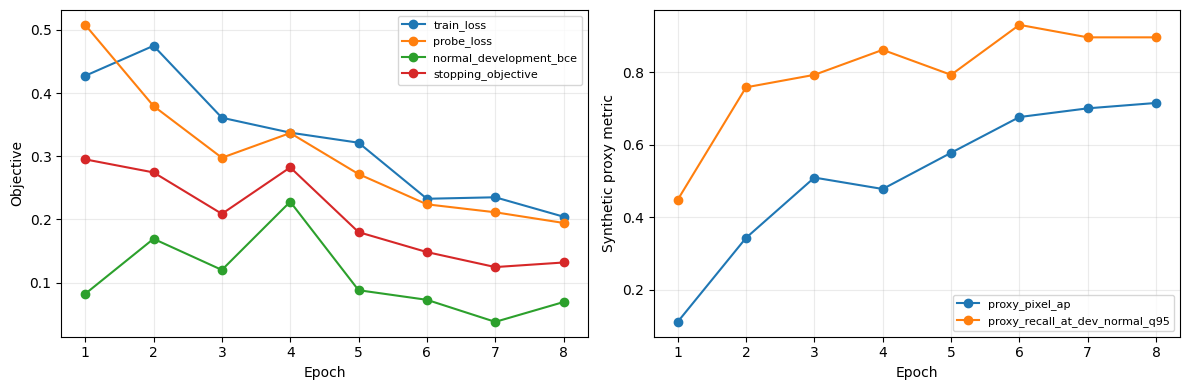

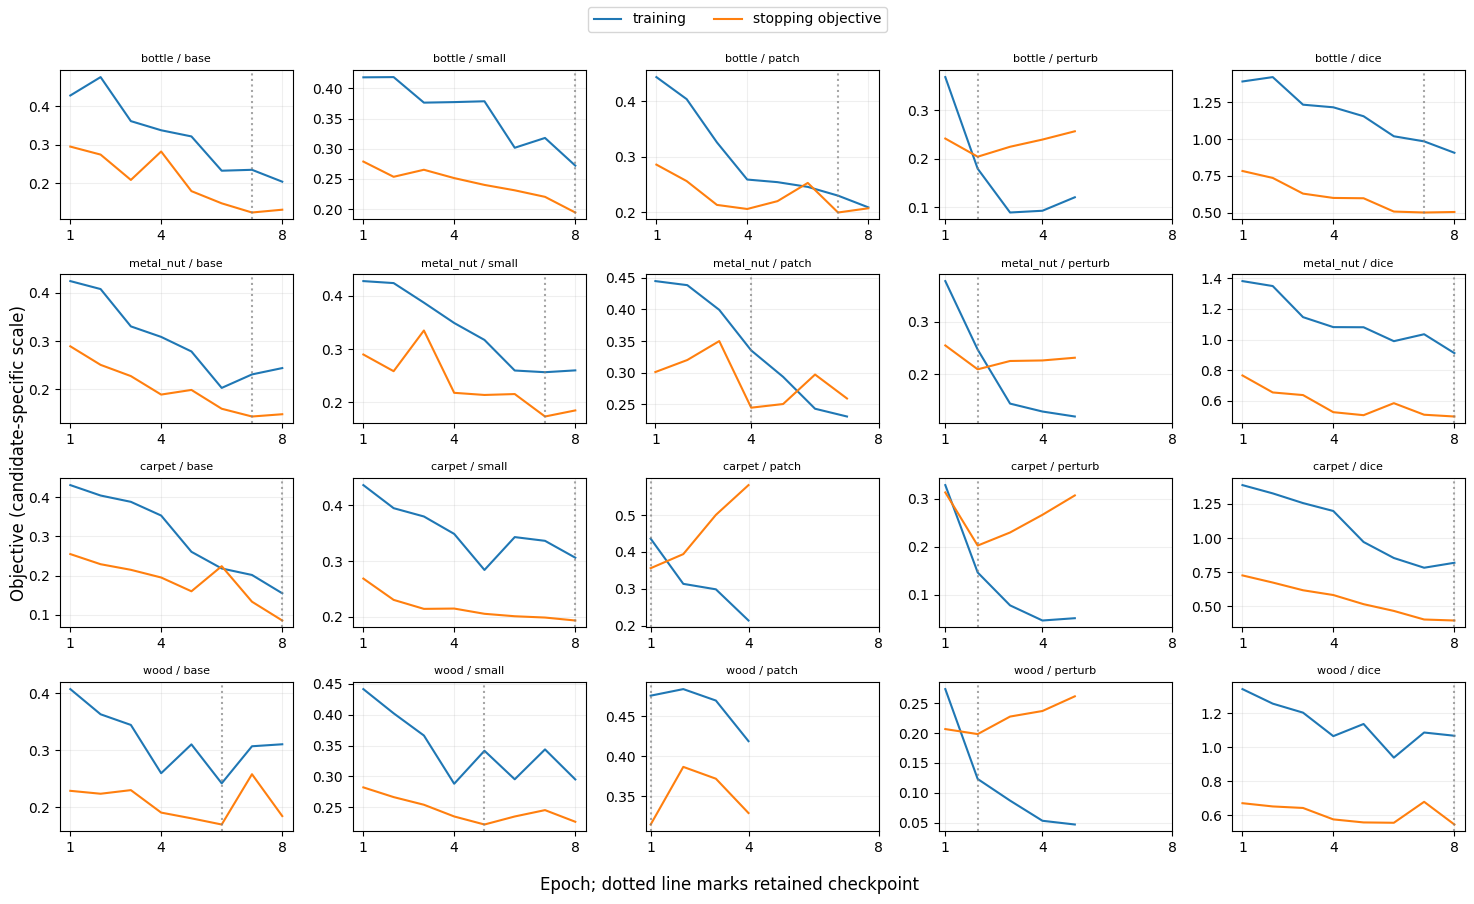

In [13]:
history=pd.read_csv(ROOT/pilot["history"])
display(history)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for key in ("train_loss","probe_loss","normal_development_bce","stopping_objective"):
    axes[0].plot(history.epoch,history[key],marker="o",label=key)
for key in ("proxy_pixel_ap","proxy_recall_at_dev_normal_q95"):
    axes[1].plot(history.epoch,history[key],marker="o",label=key)
for ax in axes:ax.set_xlabel("Epoch");ax.legend(fontsize=8);ax.grid(alpha=.25)
axes[0].set_ylabel("Objective");axes[1].set_ylabel("Synthetic proxy metric")
plt.tight_layout();plt.savefig(OUT/"pilot_curves.png",dpi=100);plt.show()

# All 20 controlled fits, including early-stopped/rejected variants.
comparison=pd.read_csv(REPORT/"development_comparison.csv")
fig,axes=plt.subplots(4,5,figsize=(15,9),squeeze=False)
for r,category in enumerate(plan["development_categories"]):
    for c,variant in enumerate(plan["variants"]):
        identifier=comparison.loc[comparison.category.eq(category)&comparison.variant.eq(variant["name"]),"experiment_id"].iloc[0]
        run=json.loads((REPORT/f"runs/{identifier}-result.json").read_text())
        assert sha256(ROOT/run["history"])==run["history_sha256"]
        curve=pd.read_csv(ROOT/run["history"])
        ax=axes[r,c]
        ax.plot(curve.epoch,curve.train_loss,label="training")
        ax.plot(curve.epoch,curve.stopping_objective,label="stopping objective")
        ax.axvline(run["best_epoch"],color="gray",linestyle=":",alpha=.7)
        ax.set_title(f"{category} / {variant['name']}",fontsize=8)
        ax.set_xticks([1,4,8]);ax.grid(alpha=.2)
fig.legend(*axes[0,0].get_legend_handles_labels(),loc="upper center",ncol=2)
fig.supxlabel("Epoch; dotted line marks retained checkpoint");fig.supylabel("Objective (candidate-specific scale)")
plt.tight_layout(rect=(0,0,1,.96));plt.savefig(OUT/"all_development_curves.png",dpi=100);plt.show()


The curves contain nonmonotonic normal responses and proxy operating points,
not just an improving headline. Selection follows the preregistered joint
objective. No extra epochs, test masks or post-test repairs were used to make
these curves or the later confirmation appear stronger.

The compact 20-panel grid retains every controlled fit, including nonmonotonic and early-stopped rejected configurations. Loss scales differ across BCE/Dice candidates; selection compares common proxy metrics instead of ranking these raw loss heights.

## 14. Capacity experiment

Compare width 8 and width 16 on the same four predetermined categories,
seeds, probe masks, data policy and optimizer. This is a controlled small search,
not a grid selected from favorable official test results.

In [14]:
development_reproductions=[]
if EXECUTE_NEW_DEVELOPMENT:
    base={k:plan[k] for k in ("seed","resolution","batch_size","learning_rate","weight_decay","max_epochs","minimum_epochs","patience","normal_probability","positive_weight")}
    for variant in plan["variants"]:
        for category in plan["development_categories"]:
            config=dict(base,**variant)
            if EXECUTE_NEW_PILOT and variant["name"]=="base" and category=="bottle":
                reproduced=pilot
            else:
                reproduced=train_experiment(f"{RUN_PREFIX}-dev-{variant['name']}-{category}",category,config,
                    "Explicit registered reproduction of bounded development; no new policy selection",phase="development")
            development_reproductions.append({"experiment_id":reproduced["experiment_id"],"category":category,"variant":variant["name"],**reproduced["selected_development_metrics"]})
    display(pd.DataFrame(development_reproductions))
development=pd.read_csv(REPORT/"development_comparison.csv")
development_macro=pd.read_csv(REPORT/"development_macro.csv").set_index("variant")
display(development[development.variant.isin(["base","small"])])
display(development_macro.loc[["base","small"]])

,variant,category,experiment_id,proxy_recall,proxy_pixel_ap,proxy_image_auroc,best_epoch,parameters,peak_vram_gib,training_seconds
0,base,bottle,01-pilot-base-bottle-s2026-v1,0.896552,0.700635,0.932224,7,83857,0.509518,13.985106
1,base,metal_nut,01-dev-base-metal_nut-s2026-v1,0.833333,0.657979,0.925556,7,83857,0.514767,28.268816
2,base,carpet,01-dev-base-carpet-s2026-v1,0.897436,0.825642,0.973702,8,83857,0.540646,41.694338
3,base,wood,01-dev-base-wood-s2026-v1,0.617647,0.570191,0.756920,6,83857,0.523922,36.136055
4,small,bottle,01-dev-small-bottle-s2026-v1,0.896552,0.694641,0.965517,8,21193,0.321669,10.821231
5,small,metal_nut,01-dev-small-metal_nut-s2026-v1,0.933333,0.662711,0.943333,7,21193,0.326918,14.896113
6,small,carpet,01-dev-small-carpet-s2026-v1,0.615385,0.646088,0.811966,8,21193,0.352797,19.526022
7,small,wood,01-dev-small-wood-s2026-v1,0.617647,0.544728,0.790657,5,21193,0.336745,13.707824


,proxy_recall,proxy_pixel_ap,parameters,best_epoch,peak_vram_gib,training_seconds
variant,,,,,,
base,0.811242,0.688612,83857,7.0,0.540646,120.084314
small,0.765729,0.637042,21193,7.5,0.352797,58.951189


The smaller model reduced parameter count and memory but had lower macro
proxy recall/AP. This result justifies capacity only on the synthetic development
task. It does not establish that a larger CNN universally detects real anomalies.

## 15. Synthetic-design experiments

Patch-only and perturbation-only candidates train against the same fixed
mixed proxy as the baseline. Keeping the evaluation generator independent of each
candidate avoids giving an ablation a custom, easier validation target.

,variant,category,experiment_id,proxy_recall,proxy_pixel_ap,proxy_image_auroc,best_epoch,parameters,peak_vram_gib,training_seconds
0,base,bottle,01-pilot-base-bottle-s2026-v1,0.896552,0.700635,0.932224,7,83857,0.509518,13.985106
1,base,metal_nut,01-dev-base-metal_nut-s2026-v1,0.833333,0.657979,0.925556,7,83857,0.514767,28.268816
2,base,carpet,01-dev-base-carpet-s2026-v1,0.897436,0.825642,0.973702,8,83857,0.540646,41.694338
3,base,wood,01-dev-base-wood-s2026-v1,0.617647,0.570191,0.756920,6,83857,0.523922,36.136055
8,patch,bottle,01-dev-patch-bottle-s2026-v1,0.517241,0.335321,0.697979,7,83857,0.509029,15.375963
9,patch,metal_nut,01-dev-patch-metal_nut-s2026-v1,0.500000,0.346762,0.777778,4,83857,0.514767,13.849144
10,patch,carpet,01-dev-patch-carpet-s2026-v1,0.179487,0.119113,0.566075,1,83857,0.540646,9.629144
11,patch,wood,01-dev-patch-wood-s2026-v1,0.058824,0.040087,0.558824,1,83857,0.523922,8.391716
12,perturb,bottle,01-dev-perturb-bottle-s2026-v1,0.517241,0.482167,0.766944,2,83857,0.509029,8.865034
13,perturb,metal_nut,01-dev-perturb-metal_nut-s2026-v1,0.600000,0.464241,0.783333,2,83857,0.514767,9.240583


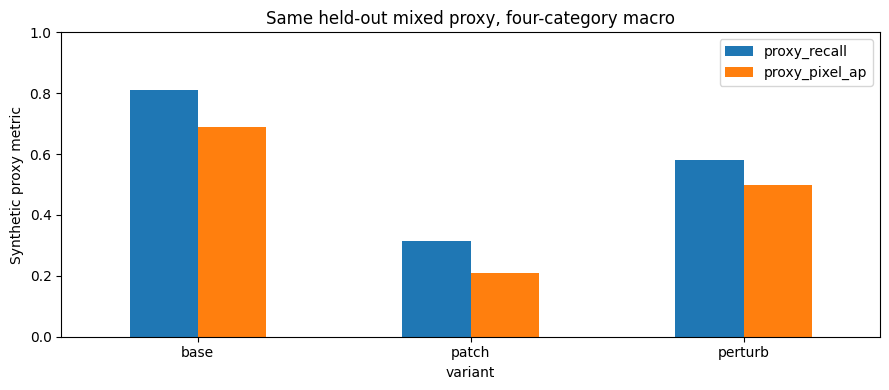

In [15]:
display(development[development.variant.isin(["base","patch","perturb"])])
development_macro.loc[["base","patch","perturb"],["proxy_recall","proxy_pixel_ap"]].plot.bar(figsize=(9,4),ylim=(0,1))
plt.ylabel("Synthetic proxy metric");plt.title("Same held-out mixed proxy, four-category macro")
plt.xticks(rotation=0);plt.tight_layout();plt.savefig(OUT/"synthetic_ablation.png",dpi=100);plt.show()

Patch-only recall averaged 0.314 versus 0.811 for mixed BCE. Its weak transfer
to the held-out proxy is retained as an unsuccessful configuration, with all
curves/checkpoints available. Mixing edits helps this proxy; real industrial
defects remain a separate distribution and are not used to select the generator.

## 16. BCE versus BCE plus Dice

The Dice ablation changes only Dice weight from zero to one. Positive BCE
weight, normal sampling, capacity, optimizer and resolution remain fixed. Early
stopping objectives are used within each candidate; cross-candidate selection
compares the same proxy recall and pixel AP instead of incomparable loss scales.

In [16]:
display(development[development.variant.isin(["base","dice"])])
display(development_macro.loc[["base","dice"]])
comparison=development.pivot(index="category",columns="variant",values="proxy_pixel_ap")
display(comparison[["base","dice"]].assign(difference=lambda d:d.dice-d.base))

,variant,category,experiment_id,proxy_recall,proxy_pixel_ap,proxy_image_auroc,best_epoch,parameters,peak_vram_gib,training_seconds
0,base,bottle,01-pilot-base-bottle-s2026-v1,0.896552,0.700635,0.932224,7,83857,0.509518,13.985106
1,base,metal_nut,01-dev-base-metal_nut-s2026-v1,0.833333,0.657979,0.925556,7,83857,0.514767,28.268816
2,base,carpet,01-dev-base-carpet-s2026-v1,0.897436,0.825642,0.973702,8,83857,0.540646,41.694338
3,base,wood,01-dev-base-wood-s2026-v1,0.617647,0.570191,0.756920,6,83857,0.523922,36.136055
16,dice,bottle,01-dev-dice-bottle-s2026-v1,0.931034,0.703386,0.964328,7,83857,0.509029,13.845991
17,dice,metal_nut,01-dev-dice-metal_nut-s2026-v1,0.900000,0.708455,0.942222,8,83857,0.514767,15.871503
18,dice,carpet,01-dev-dice-carpet-s2026-v1,0.948718,0.853164,0.976331,8,83857,0.540646,20.983695
19,dice,wood,01-dev-dice-wood-s2026-v1,0.617647,0.599961,0.789792,8,83857,0.523922,16.066128


,proxy_recall,proxy_pixel_ap,parameters,best_epoch,peak_vram_gib,training_seconds
variant,,,,,,
base,0.811242,0.688612,83857,7.0,0.540646,120.084314
dice,0.849350,0.716241,83857,8.0,0.540646,66.767317


variant,base,dice,difference
category,,,
bottle,0.700635,0.703386,0.002751
carpet,0.825642,0.853164,0.027522
metal_nut,0.657979,0.708455,0.050476
wood,0.570191,0.599961,0.029770


Mixed BCE+Dice ranked first: macro proxy recall 0.849 and pixel AP 0.716.
Four categories are a development convenience, not a large independent sample;
this is not a significance claim or evidence that real-test localization improved.

## 17. Resolution experiment decision

Resolution changes were conditional on weak pilot learning plus available
VRAM. The pilot learned useful proxy structure, and the bounded baseline did not
need another search. We therefore explicitly did not run a resolution ablation.
Small-real-defect loss from 256×256 remains a limitation, not a tuned-away result.

In [17]:
print("Resolution tested:",plan["resolution"])
print("Resolution experiment:",frozen["resolution_experiment"])
print("Pilot selected proxy pixel AP:",pilot["selected_development_metrics"]["proxy_pixel_ap"])
print("Pilot peak allocated GiB:",pilot["peak_allocated_bytes"]/2**30)
print("Native square widths:",sorted({v["width"] for v in eda["native_resolution_by_category"].values()}))

Resolution tested: 256
Resolution experiment: not conducted; pilot learned, no extra search justified
Pilot selected proxy pixel AP: 0.7006346334601629
Pilot peak allocated GiB: 0.5095176696777344
Native square widths: [700, 800, 840, 900, 1000, 1024]


Available VRAM alone is not a reason to expand the search. The baseline keeps
the preregistered 256×256 resolution and reports any small-defect/localization
failures honestly. No resolution was selected by looking at official test masks.

## 18. Selection, preserved decisions and frozen policy

All five configurations and all 20 category fits remain visible. Selection
maximizes macro proxy recall, then proxy pixel AP, then favors fewer parameters.
The selected variant's median best epoch is eight. Final runs use fresh models,
all fitting normals, three seeds and this fixed duration; no post-test changes.

In [18]:
display(development_macro)
decisions=[]
for identifier in frozen["development_run_ids"]:
    event=json.loads((ROOT/f"experiments/{identifier}-decision.json").read_text())
    decisions.append({"experiment_id":identifier,"decision":event["decision"],"interpretation":event["interpretation"]})
display(pd.DataFrame(decisions))
display(frozen["configuration"])
print("Frozen policy SHA256:",sha256(ROOT/"configs/basic_cnn_frozen.json"))
print("Final categories:",frozen["categories"],"seeds:",frozen["seeds"])
print("Frozen timestamp:",frozen["frozen_at_utc"])

,proxy_recall,proxy_pixel_ap,parameters,best_epoch,peak_vram_gib,training_seconds
variant,,,,,,
dice,0.849350,0.716241,83857,8.0,0.540646,66.767317
base,0.811242,0.688612,83857,7.0,0.540646,120.084314
small,0.765729,0.637042,21193,7.5,0.352797,58.951189
perturb,0.582101,0.497647,83857,2.0,0.540646,41.114069
patch,0.313888,0.210321,83857,2.5,0.540646,47.245967


,experiment_id,decision,interpretation
0,01-pilot-base-bottle-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
1,01-dev-base-metal_nut-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
2,01-dev-base-carpet-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
3,01-dev-base-wood-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
4,01-dev-small-bottle-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
5,01-dev-small-metal_nut-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
6,01-dev-small-carpet-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
7,01-dev-small-wood-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
8,01-dev-patch-bottle-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...
9,01-dev-patch-metal_nut-s2026-v1,reject,Predeclared macro proxy ranking selected dice;...


{'seed': 2026,
 'resolution': 256,
 'batch_size': 16,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'max_epochs': 8,
 'minimum_epochs': 3,
 'patience': 3,
 'normal_probability': 0.5,
 'positive_weight': 8.0,
 'name': 'dice',
 'width': 16,
 'synthetic': 'mixed',
 'dice_weight': 1.0}

Frozen policy SHA256: 13b8d6a81a4e0f40af8732bd4ad58376554b6006ce0bb0126b13f9e105fb4404
Final categories: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper'] seeds: [2026, 2027, 2028]
Frozen timestamp: 2026-11-12T06:00:15.617306+00:00


Reject means that the configuration lost the bounded comparison, not that it
was erased or never attempted. All-category training was launched only after the
pilot gate and this selection. Each category/seed begins from independent random
weights; no category-specific learned checkpoint is reused for another category.
Initialization can be identical across categories within a seed by design; their
gradient images, updates and learned weights remain separate.

### Experiment-by-experiment interpretation

**01-pilot-base-bottle-s2026-v1** — bottle, base: proxy recall 0.897, pixel AP 0.701, selected epoch 7, peak 0.510 GiB. Initial reference for this category. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-base-metal_nut-s2026-v1** — metal_nut, base: proxy recall 0.833, pixel AP 0.658, selected epoch 7, peak 0.515 GiB. Initial reference for this category. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-base-carpet-s2026-v1** — carpet, base: proxy recall 0.897, pixel AP 0.826, selected epoch 8, peak 0.541 GiB. Initial reference for this category. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-base-wood-s2026-v1** — wood, base: proxy recall 0.618, pixel AP 0.570, selected epoch 6, peak 0.524 GiB. Initial reference for this category. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-small-bottle-s2026-v1** — bottle, small: proxy recall 0.897, pixel AP 0.695, selected epoch 8, peak 0.322 GiB. Recall difference from the same-category baseline: +0.000; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-small-metal_nut-s2026-v1** — metal_nut, small: proxy recall 0.933, pixel AP 0.663, selected epoch 7, peak 0.327 GiB. Recall difference from the same-category baseline: +0.100; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-small-carpet-s2026-v1** — carpet, small: proxy recall 0.615, pixel AP 0.646, selected epoch 8, peak 0.353 GiB. Recall difference from the same-category baseline: -0.282; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-small-wood-s2026-v1** — wood, small: proxy recall 0.618, pixel AP 0.545, selected epoch 5, peak 0.337 GiB. Recall difference from the same-category baseline: +0.000; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-patch-bottle-s2026-v1** — bottle, patch: proxy recall 0.517, pixel AP 0.335, selected epoch 7, peak 0.509 GiB. Recall difference from the same-category baseline: -0.379; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-patch-metal_nut-s2026-v1** — metal_nut, patch: proxy recall 0.500, pixel AP 0.347, selected epoch 4, peak 0.515 GiB. Recall difference from the same-category baseline: -0.333; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-patch-carpet-s2026-v1** — carpet, patch: proxy recall 0.179, pixel AP 0.119, selected epoch 1, peak 0.541 GiB. Recall difference from the same-category baseline: -0.718; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-patch-wood-s2026-v1** — wood, patch: proxy recall 0.059, pixel AP 0.040, selected epoch 1, peak 0.524 GiB. Recall difference from the same-category baseline: -0.559; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-perturb-bottle-s2026-v1** — bottle, perturb: proxy recall 0.517, pixel AP 0.482, selected epoch 2, peak 0.509 GiB. Recall difference from the same-category baseline: -0.379; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-perturb-metal_nut-s2026-v1** — metal_nut, perturb: proxy recall 0.600, pixel AP 0.464, selected epoch 2, peak 0.515 GiB. Recall difference from the same-category baseline: -0.233; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-perturb-carpet-s2026-v1** — carpet, perturb: proxy recall 0.564, pixel AP 0.552, selected epoch 2, peak 0.541 GiB. Recall difference from the same-category baseline: -0.333; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-perturb-wood-s2026-v1** — wood, perturb: proxy recall 0.647, pixel AP 0.492, selected epoch 2, peak 0.524 GiB. Recall difference from the same-category baseline: +0.029; this is a synthetic-proxy comparison. Decision: reject for final confirmation under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-dice-bottle-s2026-v1** — bottle, dice: proxy recall 0.931, pixel AP 0.703, selected epoch 7, peak 0.509 GiB. Recall difference from the same-category baseline: +0.034; this is a synthetic-proxy comparison. Decision: keep selected configuration under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-dice-metal_nut-s2026-v1** — metal_nut, dice: proxy recall 0.900, pixel AP 0.708, selected epoch 8, peak 0.515 GiB. Recall difference from the same-category baseline: +0.067; this is a synthetic-proxy comparison. Decision: keep selected configuration under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-dice-carpet-s2026-v1** — carpet, dice: proxy recall 0.949, pixel AP 0.853, selected epoch 8, peak 0.541 GiB. Recall difference from the same-category baseline: +0.051; this is a synthetic-proxy comparison. Decision: keep selected configuration under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

**01-dev-dice-wood-s2026-v1** — wood, dice: proxy recall 0.618, pixel AP 0.600, selected epoch 8, peak 0.524 GiB. Recall difference from the same-category baseline: +0.000; this is a synthetic-proxy comparison. Decision: keep selected configuration under the predefined macro criterion. Exact configuration, complete curve and checkpoint identity are preserved in the linked registry/run artifacts.

## 19. Image and pixel threshold calibration

Only reserved real normal calibration images set thresholds. Image alarms
use the higher q95 order statistic and strict score > threshold; q99 is a fixed
sensitivity report. Pixel decisions separately use conservative q99.5 pooled
normal pixels in 65,536 bins at model resolution. Threshold bootstrap intervals
describe finite calibration uncertainty, not guaranteed production FPR.

In [19]:
def calibrate_model(model, category, resolution, seed=2026):
    """Only the calibration manifest is read; API takes no test labels/masks."""
    rows = read_partition("calibration", category)
    images = load_resized(rows, resolution).cuda()
    logits = predict_logits(model, images)
    scores = image_scores(logits).numpy()
    primary, secondary = calibrate_normal(scores), calibrate_normal(scores, .01)
    # Conservative upper edge for the fixed quantile's bin.
    probabilities = logits.sigmoid().numpy().ravel()
    bins = 65536
    histogram = np.bincount(np.minimum((probabilities*bins).astype(np.int64), bins-1), minlength=bins)
    rank = int(np.ceil(.995*(len(probabilities)-1))) + 1
    index = int(np.searchsorted(np.cumsum(histogram), rank))
    pixel_threshold = min(1., (index+1)/bins)
    rng = np.random.default_rng(seed)
    draws = rng.choice(scores, size=(2000,len(scores)), replace=True)
    boot_thresholds = np.quantile(draws,.95,axis=1,method="higher")
    return {"category": category, "images": len(rows), "image_threshold": primary,
            "secondary_image_threshold_q99": secondary, "pixel_threshold": pixel_threshold,
            "image_quantile": .95, "pixel_quantile": .995, "pixel_bins": bins,
            "pixel_calibration_samples": len(probabilities), "pixel_score_resolution": resolution,
            "image_threshold_bootstrap_95ci": np.quantile(boot_thresholds,[.025,.975]).tolist(),
            "calibration_scores": scores.tolist(),
            "method": "normal calibration only; higher order statistic; strict score > threshold",
            "source_paths_sha256": config_hash(rows[["path","sha256"]].to_dict("records"))}

calibrations=[]
for identifier in pd.read_csv(REPORT/"all_runs.csv").experiment_id:
    path=REPORT/f"evaluation/{identifier}-calibration.json"
    item=json.loads(path.read_text());item["seed"]=int(path.name.split("-s")[-1].split("-")[0])
    calibrations.append({k:item[k] for k in ("category","seed","images","image_threshold","secondary_image_threshold_q99","pixel_threshold","image_threshold_bootstrap_95ci")})
calibration_table=pd.DataFrame(calibrations)
display(calibration_table[calibration_table.seed.eq(2026)].sort_values("category"))
print("Smallest normal calibration sample:",int(calibration_table.images.min()))

,category,seed,images,image_threshold,secondary_image_threshold_q99,pixel_threshold,image_threshold_bootstrap_95ci
0,bottle,2026,31,0.243714,0.250814,0.036835,"[0.08694814890623093, 0.25081387162208557]"
1,cable,2026,33,0.785469,0.893124,0.348129,"[0.598772406578064, 0.8931243419647217]"
2,capsule,2026,32,0.999197,0.999821,0.939056,"[0.9830536246299744, 0.9998206496238708]"
3,carpet,2026,42,0.930507,0.973713,0.526733,"[0.9099642038345337, 0.9737128019332886]"
4,grid,2026,39,0.984499,0.998527,0.334229,"[0.9196788668632507, 0.9985268115997314]"
5,hazelnut,2026,58,0.991193,0.996245,0.883896,"[0.9809228777885437, 0.9962449669837952]"
6,leather,2026,36,0.747122,0.798856,0.502731,"[0.6370024681091309, 0.7988564372062683]"
7,metal_nut,2026,33,0.996490,0.998726,0.759033,"[0.9713247418403625, 0.9987264275550842]"
8,pill,2026,40,0.998912,0.999796,0.745972,"[0.9967617988586426, 0.9997956156730652]"
9,screw,2026,48,0.864021,0.997964,0.509308,"[0.7811749577522278, 0.9979640245437622]"


Smallest normal calibration sample: 9


Toothbrush has only nine calibration normals; the q95 rule becomes the
sample maximum and can still miss population extremes. The pixel threshold is
not the image threshold. Native map interpolation can change pixel FPR relative
to calibration resolution. Neither threshold maximizes real-test F1 or uses masks.

## 20. Fresh all-category fits and frozen one-shot evaluation

Actual phase commands were `scripts/run_basic_cnn.py final-train` then
`scripts/run_basic_cnn.py final-evaluate`. The exact evaluator source below shows
freeze/hash guards, calibration before test access, native original masks,
one-pass exact ranking metrics and immutable evaluation reservation. This replay
loads recorded results; the optional reproduction loop gets new IDs and must be
reported as a repeat, not an untouched new confirmation.

In [20]:
from anomaly_detection.cnn_evaluation import evaluate_frozen
display(Code(inspect.getsource(evaluate_frozen),language="python"))
reproduced_evaluations={}
if EXECUTE_NEW_CONFIRMATION:
    for seed in frozen["seeds"]:
        for category in CATEGORIES:
            config=dict(frozen["configuration"],seed=seed)
            trained=train_experiment(f"{RUN_PREFIX}-final-{category}-s{seed}",category,config,
                "Explicit registered reproduction of frozen final policy",phase="final")
            reproduced=evaluate_frozen(f"{RUN_PREFIX}-test-{category}-s{seed}",trained,sha256(ROOT/"configs/basic_cnn_frozen.json"))
            reproduced_evaluations[(category,seed)]=reproduced
all_runs=pd.read_csv(REPORT/"all_runs.csv")
assert len(all_runs)==45 and all_runs.groupby("category").size().eq(3).all()
evaluations={}
for identifier in all_runs.experiment_id:
    path=REPORT/f"evaluation/{identifier}-result.json"
    result=json.loads(path.read_text());evaluations[(result["category"],result["seed"])]=result
assert len(evaluations)==45
if reproduced_evaluations:
    reproduced_table=pd.DataFrame([{k:r[k] for k in ("experiment_id","category","seed","image_auroc","image_ap","pixel_auroc","pixel_ap","au_pro","recall","fpr")} for r in reproduced_evaluations.values()])
    display(reproduced_table)
    reproduced_table.to_csv(OUT/f"{RUN_PREFIX}-metrics.csv",index=False,lineterminator="\n")
display(all_runs[["category","seed","image_auroc","pixel_ap","recall","fpr"]])

def evaluate_frozen(identifier, training_result, freeze_sha256):
    """One immutable evaluation reservation per category/seed; never retries itself."""
    from .cnn_research import code_identity
    freeze_path=ROOT/"configs/basic_cnn_frozen.json"
    if sha256(freeze_path)!=freeze_sha256:raise ValueError("Frozen confirmation identity mismatch")
    frozen=json.loads(freeze_path.read_text())
    expected=dict(frozen["configuration"],seed=training_result["configuration"]["seed"])
    if expected!=training_result["configuration"] or expected["seed"] not in frozen["seeds"]:
        raise ValueError("Training configuration differs from frozen policy")
    if training_result["category"] not in frozen["categories"]:
        raise ValueError("Unregistered category")
    if sha256(Path(__file__))!=frozen["evaluation_source_sha256"]:
        raise ValueError("Evaluation implementation changed after freeze")
    if sha256(Path(__file__).with_name("pixel_metrics.py"))!=frozen["pixel_metric_source_sha256"]:
        raise ValueError("Pixel metric implementation changed after freeze")
    result_dir=ROOT/"reports/basic_cnn/evaluation"
    result_dir.mkdir(parents=True,exist_ok=True)
    local=ROOT/"outputs/basic_cnn"/identifier
    local.mkdir(parents=True,exist_ok=False)
    category=training_result["category"]
    config=training_result["configuration"]
    entry={"experiment_id":identifier+"-start","model_family":"BasicCNN","categories":[category],
           "hypothesis":"Frozen synthetic-supervised CNN transfers to official real defects; no further selection",
           "preprocessing":{"resolution":config["resolution"],"native_map":"bilinear, align_corners=False"},
           "hyperparameters":config,"seed":config["seed"],
           "environment":json.loads((ROOT/"reports/environment.json").read_text()),
           "training":{"training_experiment":training_result["experiment_id"],"freeze_sha256":freeze_sha256,
                       "code":code_identity(),"evaluation_source_sha256":sha256(Path(__file__)),
                       "pixel_metric_source_sha256":sha256(Path(__file__).with_name("pixel_metrics.py"))},
           "metrics":{},"calibration":{},"paths":{"local":local.relative_to(ROOT).as_posix()},
           "interpretation":"Reserved before calibration/test inference","decision":"frozen evaluation","status":"started"}
    record(ROOT/"experiments",entry)
    started=time.perf_counter()
    try:
        checkpoint=ROOT/training_result["checkpoint"]
        if sha256(checkpoint)!=training_result["checkpoint_sha256"]:raise ValueError("Checkpoint identity changed")
        model,saved=load_checkpoint(checkpoint)
        if saved["category"]!=category or saved["training_phase"]!="final":
            raise ValueError("Expected a fresh category-specific final checkpoint")
        # Calibration occurs and is saved BEFORE test rows/images are loaded.
        calibration=calibrate_model(model,category,config["resolution"],config["seed"])
        with (result_dir/f"{identifier}-calibration.json").open("x") as stream:json.dump(calibration,stream,indent=2)
        rows=read_partition("test",category)
        data_root=autodiscover_data_root(ROOT)
        images=load_resized(rows,config["resolution"],allow_test=True).cuda()
        logits=predict_logits(model,images,config["batch_size"])
        maps=logits.sigmoid().numpy()[:,0]
        # Primary maximum score at model resolution, declared before test access.
        scores=maps.reshape(len(maps),-1).max(1)
        labels=rows["mask"].notna().astype(int).to_numpy()
        image_result=binary_metrics(labels,scores,calibration["image_threshold"])
        tn,fp,fn,tp=np.asarray(image_result["confusion_matrix"]).ravel()
        image_counts={"tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp)}
        secondary=binary_metrics(labels,scores,calibration["secondary_image_threshold_q99"])
        table=rows[["path","category","mask"]].copy()
        table["defect"]=rows.path.str.split("/").st

,category,seed,image_auroc,pixel_ap,recall,fpr
0,bottle,2026,0.776190,0.240282,0.380952,0.000000
1,cable,2026,0.449963,0.210854,0.010870,0.017241
2,capsule,2026,0.446749,0.027285,0.128440,0.000000
3,carpet,2026,0.530498,0.119516,0.224719,0.214286
4,grid,2026,0.969089,0.245427,0.771930,0.047619
5,hazelnut,2026,0.814643,0.413514,0.642857,0.000000
6,leather,2026,0.818954,0.334835,0.826087,0.468750
7,metal_nut,2026,0.500000,0.268937,0.193548,0.136364
8,pill,2026,0.772504,0.195328,0.432624,0.076923
9,screw,2026,0.024185,0.006070,0.042017,0.853659


Each category/seed was evaluated once under the frozen policy. Replaying
saved tables or rendering retained maps is not new inference or tuning. The
selected configuration is retained even when later real-test results are weak;
test-driven repairs would require a separate, explicitly exploratory protocol.

## 21. Image and exact native pixel metrics with uncertainty

Image AUROC/AP use the existing metric utilities. Native pixel AUROC/AP and
normalized AU-PRO use one sorted score sweep, equal 8-connected region weights
and background FPR ≤0.30. Chunk boundaries preserve tied scores exactly. Whole-image
bootstrap uses 2,000 replicates: image metrics exact, pixel confidence intervals a
disclosed 4,096-bin approximation. Point estimates do not downsample masks/pixels.

In [21]:
def exact_pixel_metrics(scores, labels, region_weights, region_count, chunk_size=1_000_000, max_fpr=.3):
    scores, labels, region_weights = (np.asarray(v) for v in (scores, labels, region_weights))
    if scores.ndim != 1 or labels.shape != scores.shape or region_weights.shape != scores.shape:
        raise ValueError("Matching flat score, binary truth and region-weight vectors required")
    positives = int(labels.sum(dtype=np.int64))
    negatives = len(labels)-positives
    if not positives or not negatives or not region_count:
        raise ValueError("Both pixel classes and at least one defect region required")
    if not 0 < max_fpr <= 1 or chunk_size < 1:
        raise ValueError("Invalid integration limit/chunk size")
    # Finite values and binary truth checked in bounded chunks before sorting.
    for start in range(0, len(scores), chunk_size):
        end = start+chunk_size
        if not np.isfinite(scores[start:end]).all() or not np.isin(labels[start:end], [0,1]).all():
            raise ValueError("Invalid pixel scores/labels")
    order = np.argsort(scores, kind="stable")[::-1]
    state = dict(tp=0, fp=0, regions=0., auroc=0., ap=0., aupro=0.)

    def consume(pos, neg, region):
        if not len(pos): return
        tp = state["tp"] + np.cumsum(pos, dtype=np.int64)
        fp = state["fp"] + np.cumsum(neg, dtype=np.int64)
        rg = state["regions"] + np.cumsum(region, dtype=np.float64)
        x = np.r_[state["fp"]/negatives, fp/negatives]
        y = np.r_[state["tp"]/positives, tp/positives]
        state["auroc"] += float(np.trapezoid(y, x))
        state["ap"] += float(np.sum(pos/positives * tp/(tp+fp)))
        pro = np.r_[state["regions"]/region_count, rg/region_count]
        if x[0] < max_fpr:
            keep = x < max_fpr
            clipped_x, clipped_pro = x[keep], pro[keep]
            if x[-1] >= max_fpr:
                clipped_x = np.r_[clipped_x, max_fpr]
                clipped_pro = np.r_[clipped_pro, np.interp(max_fpr, x, pro)]
            state["aupro"] += float(np.trapezoid(clipped_pro, clipped_x))/max_fpr
        state.update(tp=int(tp[-1]), fp=int(fp[-1]), regions=float(rg[-1]))

    pending = None
    for start in range(0, len(order), chunk_size):
        indices = order[start:start+chunk_size]
        values = scores[indices]
        boundaries = np.r_[0, np.flatnonzero(values[1:] != values[:-1])+1]
        pos = np.add.reduceat(labels[indices], boundaries, dtype=np.int64)
        count = np.diff(np.r_[boundaries, len(indices)])
        neg = count-pos
        region = np.add.reduceat(region_weights[indices], boundaries, dtype=np.float64)
        if pending is not None:
            if pending[0] == values[0]:
                pos[0] += pending[1]; neg[0] += pending[2]; region[0] += pending[3]
            else:
                consume(np.array([pending[1]]), np.array([pending[2]]), np.array([pending[3]]))
        consume(pos[:-1], neg[:-1], region[:-1])
        pending = (values[boundaries[-1]], int(pos[-1]), int(neg[-1]), float(region[-1]))
    if pending is not None:
        consume(np.array([pending[1]]), np.array([pending[2]]), np.array([pending[3]]))
    return {"pixel_auroc": state["auroc"], "pixel_ap": state["ap"], "au_pro": state["aupro"],
            "positive_pixels": positives, "negative_pixels": negatives, "regions": int(region_count),
            "method": "exact native-resolution score sweep, 8-connected equal-weight regions"}

fixture=binary_metrics([0,0,1,1],[.1,.4,.35,.8],.5)
assert fixture["auroc"]==.75 and np.isclose(fixture["ap"],5/6)
metric_summary=json.loads((REPORT/"summary.json").read_text())
display(pd.DataFrame(metric_summary["macro"]).T)
print(metric_summary["bootstrap_scope"])
print("Confusion ordering: [[TN,FP],[FN,TP]]; AP is stepwise average precision.")
display(metric_summary["metric_edge_cases"])

,mean,seed_std,image_bootstrap_95ci,bootstrap_target,valid_macro_replicates
image_auroc,0.712589,0.021535,"[0.6950766876490477, 0.7303867835312444]",exact image metric,2000
image_ap,0.858954,0.012583,"[0.8461642417521088, 0.8760253076423806]",exact image metric,2000
pixel_auroc,0.785832,0.024923,"[0.7779351759327134, 0.795878987262732]",4096-bin pixel approximation,2000
pixel_ap,0.235382,0.010391,"[0.2173959222643338, 0.24344908351519937]",4096-bin pixel approximation,2000
au_pro,0.549807,0.035456,"[0.5363492245288088, 0.5635953370381358]",4096-bin pixel approximation,2000
recall,0.40176,0.016653,"[0.3818311417026175, 0.4224456137378974]",exact image metric,2000
fpr,0.098341,0.050615,"[0.08246524204694579, 0.11451399483848151]",exact image metric,2000
precision,0.873299,0.044672,"[0.8356622736235548, 0.897348508265896]",exact image metric,2000
f1,0.510593,0.021044,"[0.48935421846504235, 0.5294172484596104]",exact image metric,2000


whole-image within category; same resamples across seeds, independent categories; pixel CI 4096-bin approximation, point estimates exact
Confusion ordering: [[TN,FP],[FN,TP]]; AP is stepwise average precision.


{'image_runs_with_no_alarms': 0,
 'pixel_runs_with_no_alarms': 0,
 'precision_convention': 'Immutable foundation binary_metrics uses zero_division=0; undefined cases explicitly flagged. Do not mistake zero-alert precision for a measured probability.',
 'image_precision_defined_run_mean': 0.8732991092362754,
 'pixel_precision_defined_run_mean': 0.3550448672065778,
 'f1': 'Zero when no predicted positives and actual positives exist; directly 2TP/(2TP+FP+FN)',
 'ranking_metrics': 'All category test sets contain both classes; no AUROC/AP/AU-PRO undefined cases'}

Pixel AP is sensitive to tiny defect prevalence; a high pixel AUROC alone
can hide poor localization. Undefined metrics would be null with reasons; all
categories here contain both classes. Seed standard deviation and conditional
image-bootstrap intervals quantify different uncertainties. Three seeds and one
benchmark still do not establish production generalization. Pixel intervals target
the binned approximation: quantization can materially bias pixel AP even when
AUROC changes little. Exact point estimates remain primary; the summary reports
the measured binned-minus-exact bias rather than presenting these as exact-pixel
confidence intervals. The foundation utility's zero-division convention is kept
in immutable raw records, with no-alarm precision explicitly flagged and defined-
run coverage reported. Public operating tables mark undefined precision N/A;
zero F1 remains valid because real defects exist. No undefined ranking metric is
silently replaced by zero.

## 22. Confusion matrices and operating points

Show all 15 seed-2026 image confusion matrices, with no category omitted.
Thresholds were fixed from calibration normals. Compare the predetermined q99
policy to primary q95 without selecting a winner after observing test labels.

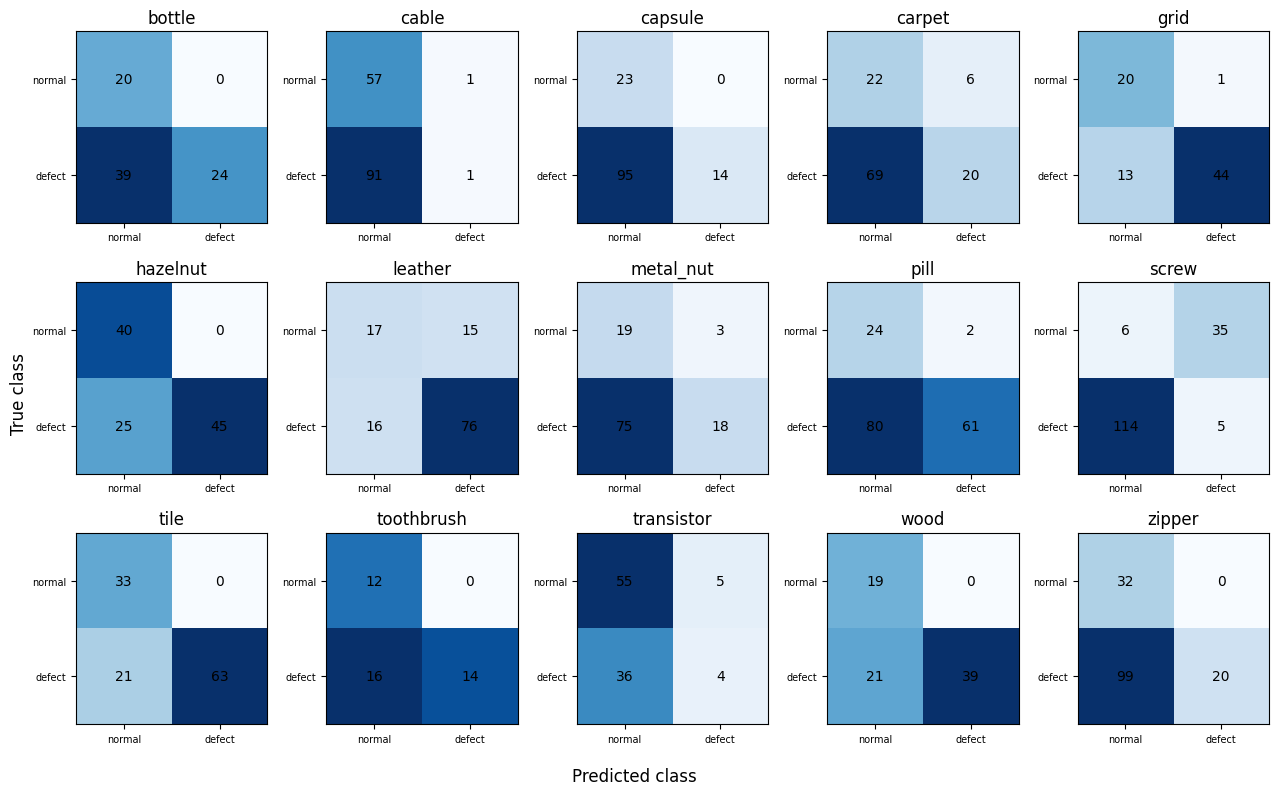

,recall,fpr,precision,f1,q99_recall,q99_fpr,pixel_recall,pixel_fpr,pixel_precision,pixel_f1
category,,,,,,,,,,
bottle,0.444444,0.033333,0.978405,0.609029,0.412698,0.000000,0.128739,0.007693,0.504654,0.203239
cable,0.079710,0.057471,0.600000,0.135010,0.021739,0.011494,0.069527,0.004789,0.281856,0.110999
capsule,0.116208,0.028986,0.939394,0.206526,0.091743,0.028986,0.043028,0.005422,0.067408,0.052442
carpet,0.329588,0.214286,0.830054,0.468275,0.187266,0.059524,0.198682,0.006411,0.333720,0.247373
grid,0.748538,0.047619,0.977089,0.847582,0.672515,0.031746,0.622966,0.025317,0.146333,0.236967
hazelnut,0.619048,0.000000,1.000000,0.763769,0.519048,0.000000,0.324442,0.003300,0.679497,0.438781
leather,0.887681,0.302083,0.898817,0.890761,0.858696,0.218750,0.707331,0.020480,0.194795,0.299176
metal_nut,0.225806,0.090909,0.885714,0.353940,0.164875,0.075758,0.054240,0.004637,0.604295,0.099488
pill,0.340426,0.038462,0.981842,0.501631,0.286052,0.012821,0.148101,0.007448,0.408708,0.217132


,image_precision_defined_seeds,pixel_precision_defined_seeds
category,,
bottle,3,3
cable,3,3
capsule,3,3
carpet,3,3
grid,3,3
hazelnut,3,3
leather,3,3
metal_nut,3,3
pill,3,3


In [22]:
fig,axes=plt.subplots(3,5,figsize=(13,8))
for ax,category in zip(axes.flat,CATEGORIES):
    matrix=np.asarray(evaluations[(category,2026)]["confusion_matrix"])
    ax.imshow(matrix,cmap="Blues",vmin=0,vmax=max(1,matrix.max()))
    for (r,c),value in np.ndenumerate(matrix):ax.text(c,r,str(value),ha="center",va="center")
    ax.set_title(category);ax.set_xticks([0,1],["normal","defect"],fontsize=7)
    ax.set_yticks([0,1],["normal","defect"],fontsize=7)
fig.supxlabel("Predicted class");fig.supylabel("True class")
plt.tight_layout();plt.savefig(OUT/"all_category_confusions.png",dpi=100);plt.show()
operating=all_runs.copy()
operating.loc[~operating.precision_defined,"precision"]=np.nan
operating.loc[~operating.pixel_precision_defined,"pixel_precision"]=np.nan
display(operating.groupby("category")[["recall","fpr","precision","f1","q99_recall","q99_fpr","pixel_recall","pixel_fpr","pixel_precision","pixel_f1"]].mean())
display(operating.groupby("category")[["precision_defined","pixel_precision_defined"]].sum().rename(columns={"precision_defined":"image_precision_defined_seeds","pixel_precision_defined":"pixel_precision_defined_seeds"}))

Threshold-free ranking metrics and calibrated operating points answer
different questions. The q95 policy's observed test FPR need not equal 5%; small
calibration samples and distribution differences can produce more false alarms.
Pixel operating points remain separate and may be poor despite good ranking.

## 23. Per-category predictions, masks, maps and transparent overlays

For every category, choose the first path of each available TN/TP/FP/FN
outcome, not the most attractive heatmap. Missing outcome classes are explicitly
listed; examples are never fabricated. Reuse retained seed-2026 predictions with
no additional test inference. Probability colors use fixed [0,1] scale.

In [23]:
DATA=autodiscover_data_root(ROOT)
panel_index=[]
for category in CATEGORIES:
    result=evaluations[(category,2026)]
    maps_path=ROOT/result["local_maps"]
    if not maps_path.exists() and (category,2026) in reproduced_evaluations:
        result=reproduced_evaluations[(category,2026)]
        maps_path=ROOT/result["local_maps"]
    if not maps_path.exists():
        print("EXPLICITLY SKIPPED local licensed panel:",category,"prediction artifact is not distributed in Git. Use separately registered reproduction.")
        panel_index.append({"category":category,"figure":None,"absent_outcomes":[],"missing_local_artifact":True})
        continue
    table=pd.read_csv(REPORT/f"evaluation/{result['experiment_id']}-images.csv")
    assert sha256(maps_path)==result["maps_sha256"]
    maps=np.load(maps_path,mmap_mode="r")
    selected=[];absent=[]
    for outcome in ("TN","TP","FP","FN"):
        subset=table[table.outcome.eq(outcome)]
        if subset.empty:absent.append(outcome)
        else:selected.append((outcome,subset.index[0]))
    fig,axes=plt.subplots(len(selected),4,figsize=(10,2.6*len(selected)),squeeze=False)
    for r,(outcome,index) in enumerate(selected):
        row=table.loc[index]
        with Image.open(DATA/row.path) as image:original=np.asarray(image.convert("RGB"))
        with torch.inference_mode():
            native=F.interpolate(torch.from_numpy(np.asarray(maps[index]).copy())[None,None],size=original.shape[:2],mode="bilinear",align_corners=False).numpy()[0,0]
        if isinstance(row["mask"],str):
            with Image.open(DATA/row["mask"]) as mask_image:truth=np.asarray(mask_image)>0
        else:truth=np.zeros(original.shape[:2],dtype=bool)
        axes[r,0].imshow(original);axes[r,0].set_title(f"{outcome}: score {row.score:.3f}")
        axes[r,1].imshow(truth,cmap="gray",vmin=0,vmax=1);axes[r,1].set_title("official mask / normal zeros")
        axes[r,2].imshow(native,cmap="magma",vmin=0,vmax=1);axes[r,2].set_title("probability [0,1]")
        axes[r,3].imshow(original)
        axes[r,3].imshow(np.ma.masked_where(native<=result["calibration"]["pixel_threshold"],native),cmap="Reds",alpha=.55,vmin=0,vmax=1)
        axes[r,3].set_title("pixel-calibrated overlay")
        for ax in axes[r]:ax.axis("off")
    fig.suptitle(category+" / "+result["experiment_id"]+"; absent outcomes: "+(", ".join(absent) if absent else "none")+f"\nimage threshold={result['calibration']['image_threshold']:.6f}; pixel threshold={result['calibration']['pixel_threshold']:.6f}",fontsize=9)
    plt.tight_layout();filename=f"{category}-outcomes.png";plt.savefig(OUT/filename,dpi=90);plt.show()
    panel_index.append({"category":category,"figure":filename,"absent_outcomes":absent,"missing_local_artifact":False,
                        "paths":table.loc[[i for _,i in selected],"path"].tolist()})
(OUT/"panel_index.json").write_text(json.dumps(panel_index,indent=2)+"\n")
display(pd.DataFrame(panel_index)[["category","figure","absent_outcomes"]])

The complete local executed notebook and per-category figures retain every
available error class with raw image, ground truth, heatmap and transparent
thresholded overlay. The public notebook omits licensed dataset-pixel panels;
per-image scores/outcomes, aggregate plots and all analysis remain published.
Zero normal masks express semantic normal ground truth, not synthetic defects.

An image false negative may still show a pixel overlay because the two thresholds are separate. An image true positive need not localize the annotated region if the maximum occurs elsewhere. Both outcomes are retained explicitly.

## 24. False-positive, false-negative and defect-type analysis

Use all categories and defect types, including difficult cases. These are
post-confirmation explanations, not opportunities to change the frozen model.
Geometry loss, local synthetic shortcuts and synthetic-to-real domain gap are
possible explanations, not causal conclusions from visual inspection alone.

In [24]:
failures=all_runs[all_runs.seed.eq(2026)].set_index("category")
display(failures[["tn","fp","fn","tp","image_auroc","pixel_ap","recall","fpr","unique_image_scores","fraction_image_scores_equal_one","image_threshold"]].reindex(CATEGORIES))
per_defect=pd.read_csv(REPORT/"per_defect_results.csv")
defect_summary=per_defect.groupby(["category","defect"]).agg(images=("defective_images","first"),recall=("recall","mean"),image_auroc=("auroc","mean"),image_ap=("ap","mean"))
display(defect_summary.sort_values("recall").head(20))
display(pd.read_csv(REPORT/"texture_object.csv"))
print("All defect-type results:",REPORT.relative_to(ROOT)/"per_defect_results.csv")

,tn,fp,fn,tp,image_auroc,pixel_ap,recall,fpr,unique_image_scores,fraction_image_scores_equal_one,image_threshold
category,,,,,,,,,,,
bottle,20,0,39,24,0.776190,0.240282,0.380952,0.000000,83,0.000000,0.243714
cable,57,1,91,1,0.449963,0.210854,0.010870,0.017241,150,0.000000,0.785469
capsule,23,0,95,14,0.446749,0.027285,0.128440,0.000000,132,0.000000,0.999197
carpet,22,6,69,20,0.530498,0.119516,0.224719,0.214286,117,0.008547,0.930507
grid,20,1,13,44,0.969089,0.245427,0.771930,0.047619,59,0.243590,0.984499
hazelnut,40,0,25,45,0.814643,0.413514,0.642857,0.000000,94,0.145455,0.991193
leather,17,15,16,76,0.818954,0.334835,0.826087,0.468750,88,0.290323,0.747122
metal_nut,19,3,75,18,0.500000,0.268937,0.193548,0.136364,115,0.000000,0.996490
pill,24,2,80,61,0.772504,0.195328,0.432624,0.076923,154,0.041916,0.998912


images    recall  image_auroc  image_ap
category   defect                                                       
cable      cut_outer_insulation      10  0.000000     0.344828  0.120039
capsule    scratch                   23  0.000000     0.422810  0.472875
           faulty_imprint            22  0.000000     0.445323  0.456993
cable      missing_wire              10  0.000000     0.467241  0.151442
screw      thread_top                23  0.000000     0.158360  0.267157
           scratch_neck              25  0.013333     0.235122  0.311783
pill       scratch                   24  0.027778     0.650641  0.581892
cable      missing_cable             12  0.027778     0.468870  0.180068
screw      thread_side               23  0.028986     0.185578  0.278026
           scratch_head              24  0.055556     0.203930  0.291687
capsule    poke                      21  0.063492     0.507937  0.550332
transistor damaged_case              10  0.066667     0.630556  0.248289
cable      poke_insulation           10  0.066667     0.571839  0.222718
pill       faulty_imprint            19  0.070175     0.487179  0.459695
cable      cut_inner_insulation      14  0.071429     0.441708  0.210807
metal_nut  scratch                   23  0.072464     0.475626  0.529457
cable      cable_swap                12  0.083333     0.510536  0.224803
screw      manipulated_front         24  0.083333     0.207995  0.274403
zipper     squeezed_teeth            16  0.083333     0.582682  0.575606
hazelnut   cut                       17  0.098039     0.562745  0.446399

,kind,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
0,object,0.638761,0.815014,0.770670,0.177863,0.483068,0.267567,0.082287,0.844070,0.383549
1,texture,0.860244,0.946835,0.816155,0.350421,0.683286,0.670146,0.130448,0.931757,0.764681


All defect-type results: reports\basic_cnn\per_defect_results.csv


A missing false-positive/negative example means no such event occurred in
that category/seed, not that it was hidden. Real defects can be less conspicuous
than the synthetic proxy; high normal scores can suppress recall through normal
calibration. Eight epochs and scratch features may underfit structure or overfit
edit cues. These hypotheses motivate later models, without retroactive tuning.
The score-tie table also exposes float32 sigmoid saturation and any threshold at
one: strict score > threshold can then produce no alarms. Sigmoid scores are not
calibrated real-defect probabilities. A future raw-logit aggregation study needs
its own preregistration; it is not retroactively substituted here.

### Observed category patterns

Illustrations use seed 2026 consistently; the metrics below average all three seeds. These are observations, not proofs of causal mechanisms.

- **bottle**: image AUROC 0.748, pixel AP 0.228, recall 0.444, FPR 0.033. A retained large-break example is missed, while some broken-ring pixels are detected in another. Local defect coverage is incomplete even for image-level true positives.

- **cable**: image AUROC 0.506, pixel AP 0.113, recall 0.080, FPR 0.057. Retained maps respond to cable contents on normal and defective images; the very low recall and near-chance image ranking show poor transfer to this structured object.

- **capsule**: image AUROC 0.527, pixel AP 0.029, recall 0.116, FPR 0.029. Strong responses occur near normal capsule/background boundaries, while a small annotated bottom defect is missed. Background activation competes with the true defect.

- **carpet**: image AUROC 0.606, pixel AP 0.216, recall 0.330, FPR 0.214. One color stain is detected, but normal texture also triggers responses and another weak patch is missed. Texture membership alone does not guarantee good detection.

- **grid**: image AUROC 0.929, pixel AP 0.243, recall 0.749, FPR 0.048. Bent-grid regions can be detected, but normal deformations trigger a false positive and small annotated regions can be missed. Ranking and operating-point behavior remain distinct.

- **hazelnut**: image AUROC 0.839, pixel AP 0.426, recall 0.619, FPR 0.000. Some large defects are localized, while a thin crack is missed and normal contours receive responses. The retained examples expose limited fine-detail sensitivity.

- **leather**: image AUROC 0.917, pixel AP 0.401, recall 0.888, FPR 0.302. The model detects some spots but activates on normal grain and misses a fine cut. High image ranking coexists with a high false-positive rate under the frozen normal-calibration rule.

- **metal_nut**: image AUROC 0.629, pixel AP 0.298, recall 0.226, FPR 0.091. Normal metallic contours can have near-saturated responses. A bent/missing region may still be missed; a correct image alarm can arise away from part of the annotated defect.

- **pill**: image AUROC 0.754, pixel AP 0.206, recall 0.340, FPR 0.038. Retained maps emphasize the pill outline and some ordinary surface regions. Small annotated spots and unrelated maximum responses complicate localization and image scoring.

- **screw**: image AUROC 0.199, pixel AP 0.006, recall 0.036, FPR 0.496. This is the weakest image-ranking category. Retained maps emphasize ordinary screw/thread structure; a normal screw alarms strongly while small annotated defects can receive little response. Scores are not reversed after observing this result.

- **tile**: image AUROC 0.903, pixel AP 0.564, recall 0.718, FPR 0.071. Some crack geometry is localized well. A retained image false negative still has a visible pixel overlay, illustrating the separate image and pixel thresholds.

- **toothbrush**: image AUROC 0.706, pixel AP 0.086, recall 0.389, FPR 0.028. Maps respond to repeated bristle rows in normals and defects. Displaced bristles can be missed; only nine calibration normals make tail-threshold estimation especially fragile.

- **transistor**: image AUROC 0.632, pixel AP 0.085, recall 0.125, FPR 0.050. Normal leads and package contours trigger responses. A bent lead can alarm, but another annotated leg defect is missed; local intensity cues do not establish component correctness.

- **wood**: image AUROC 0.946, pixel AP 0.328, recall 0.667, FPR 0.018. Several color defects are highlighted, but a retained high-scoring image is still an image false negative under its conservative threshold. Local maps and image decisions must be assessed separately.

- **zipper**: image AUROC 0.849, pixel AP 0.300, recall 0.300, FPR 0.000. Repeated zipper structure receives responses and some defects are missed despite good image ranking. Low observed normal FPR is accompanied by limited calibrated recall.

## 25. Runtime, memory and model size

Measurements use batch 1, float32, 50 warmups and 200 synchronized timed
iterations on a calibration-normal input. Preprocess, transfer, forward and
postprocess are timed separately. End-to-end starts with memory-resident RGB
and ends with a native probability map on CPU; disk read/decode is excluded.
Power scheme/GPU context and raw timing samples are retained per experiment.
Timing uses GPU sigmoid/interpolation; exact metric restoration uses CPU float32
interpolation. Inference allocated-memory fields include the resident evaluation
input cache, so they are process footprints, not isolated model-only allocations.

In [25]:
efficiency=all_runs.groupby("category")[["training_seconds","model_p50_ms","model_p95_ms","end_to_end_p50_ms","end_to_end_p95_ms","train_peak_vram_gib","checkpoint_bytes","parameters"]].mean()
display(efficiency.reindex(CATEGORIES))
print("Maximum training VRAM GiB:",float(all_runs.train_peak_vram_gib.max()))
print("Parameter count:",int(all_runs.parameters.iloc[0]))
print("Latency boundary:",evaluations[("bottle",2026)]["latency"]["scope"])
display(evaluations[("bottle",2026)]["latency"]["power_context_at_end_of_timing"])

,training_seconds,model_p50_ms,model_p95_ms,end_to_end_p50_ms,end_to_end_p95_ms,train_peak_vram_gib,checkpoint_bytes,parameters
category,,,,,,,,
bottle,7.892708,3.769317,6.022445,13.368867,16.010852,0.452145,343117.0,83857.0
cable,8.484057,3.761300,4.931425,15.634017,18.048133,0.454037,343117.0,83857.0
capsule,9.268997,3.690650,5.392752,14.726183,17.240370,0.453304,343117.0,83857.0
carpet,13.920918,3.684367,5.016903,14.961483,17.548760,0.462764,343117.0,83857.0
grid,10.832299,3.207300,4.822390,14.466900,17.766400,0.460933,343117.0,83857.0
hazelnut,21.235942,3.439683,5.146650,15.023367,17.991762,0.480465,343117.0,83857.0
leather,11.741614,3.632117,5.183567,15.056283,17.925558,0.457333,343117.0,83857.0
metal_nut,7.591351,3.659267,5.328182,10.541817,13.013842,0.453304,343117.0,83857.0
pill,10.976285,3.673400,5.461145,11.730067,14.446030,0.461116,343117.0,83857.0


Maximum training VRAM GiB: 0.4804649353027344
Parameter count: 83857
Latency boundary: memory-resident RGB -> native probability map on CPU; file read/decode excluded


{'windows_scheme': 'Power Scheme GUID: 381b4222-f694-41f0-9685-ff5bb260df2e  (Balanced)',
 'gpu': 'NVIDIA GeForce RTX 4060 Laptop GPU, 610.91, [N/A], P8, 210 MHz, 40'}

Means of per-run p50/p95 values are summaries of measured run percentiles,
not percentiles of a pooled production workload. Small checkpoints and low VRAM
do not compensate for missed defects. Laptop clock/power variability and excluded
disk decode limit portability of latency numbers. No architecture/config changed
after these measurements or real-test results became visible.

## 26. All 15 categories, three seeds and macro reporting

Report every category with seed variation and unweighted macro means.
Object/texture summaries are supplementary. AP is compared with test prevalence;
pixel AP with pixel foreground prevalence. Confidence intervals resample whole
images and preserve spatial dependence instead of pretending pixels independent.

,image_auroc_mean,image_auroc_std,image_ap_mean,image_ap_std,pixel_auroc_mean,pixel_auroc_std,pixel_ap_mean,pixel_ap_std,au_pro_mean,au_pro_std,recall_mean,recall_std,fpr_mean,fpr_std,precision_mean,precision_std,f1_mean,f1_std
category,,,,,,,,,,,,,,,,,,
bottle,0.748148,0.059181,0.919275,0.018838,0.780874,0.018185,0.228124,0.033047,0.433466,0.082948,0.444444,0.063492,0.033333,0.028868,0.978405,0.018818,0.609029,0.057472
cable,0.506059,0.088700,0.631426,0.083779,0.690716,0.128630,0.113341,0.086016,0.335806,0.084016,0.079710,0.084429,0.057471,0.035891,0.600000,0.173205,0.135010,0.136040
capsule,0.526659,0.124513,0.857018,0.046813,0.599108,0.121373,0.029007,0.005448,0.200637,0.055622,0.116208,0.029491,0.028986,0.050204,0.939394,0.104973,0.206526,0.049472
carpet,0.606073,0.168341,0.835802,0.081195,0.742254,0.158509,0.215738,0.141212,0.488622,0.244580,0.329588,0.096873,0.214286,0.214286,0.830054,0.149146,0.468275,0.119744
grid,0.928711,0.041841,0.974234,0.013206,0.903383,0.007058,0.242631,0.012151,0.801374,0.006315,0.748538,0.020258,0.047619,0.000000,0.977089,0.000597,0.847582,0.013132
hazelnut,0.838690,0.054164,0.923562,0.024098,0.888835,0.057068,0.426478,0.083081,0.704566,0.142532,0.619048,0.054085,0.000000,0.000000,1.000000,0.000000,0.763769,0.042048
leather,0.917346,0.086059,0.975586,0.024920,0.906427,0.071966,0.401303,0.132074,0.855895,0.134122,0.887681,0.080121,0.302083,0.236621,0.898817,0.079192,0.890761,0.052148
metal_nut,0.629032,0.134731,0.871939,0.060353,0.762377,0.065962,0.298157,0.085627,0.548068,0.121797,0.225806,0.116308,0.090909,0.078730,0.885714,0.103016,0.353940,0.154371
pill,0.753501,0.017763,0.944554,0.006279,0.833720,0.024532,0.206364,0.033463,0.770669,0.023451,0.340426,0.080552,0.038462,0.038462,0.981842,0.016359,0.501631,0.084272


,seed,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
0,2026,0.690267,0.846428,0.807773,0.236168,0.562739,0.385919,0.126545,0.831801,0.488904
1,2027,0.733240,0.871593,0.790989,0.245359,0.576982,0.400240,0.039907,0.920582,0.511947
2,2028,0.714259,0.858842,0.758734,0.224621,0.509700,0.419120,0.128571,0.867515,0.530928


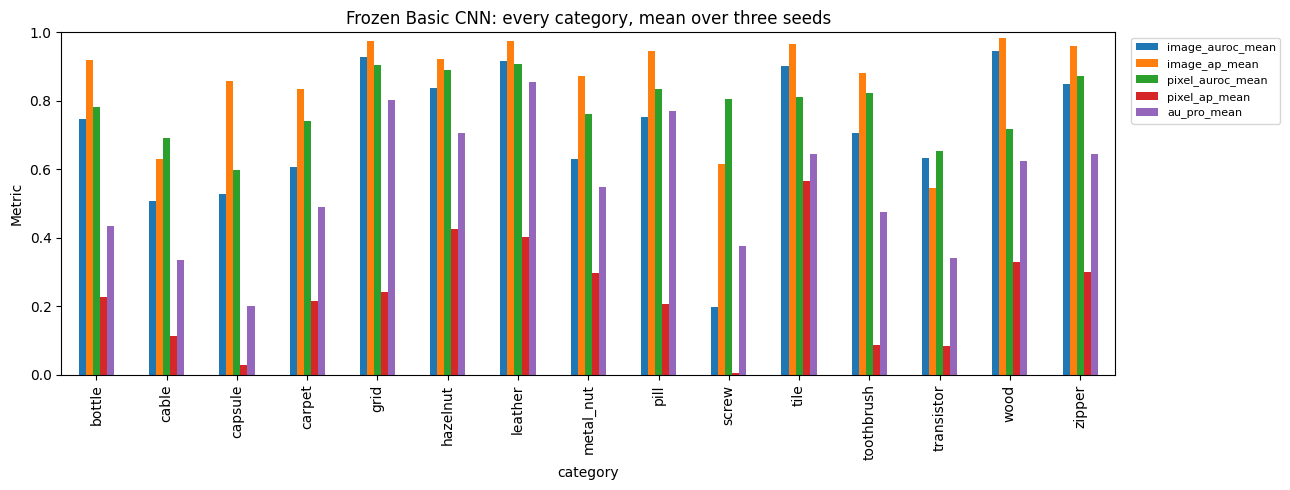

,category,image_defect_prevalence,pixel_foreground_prevalence,image_AP_mean,pixel_AP_mean
0,bottle,0.759036,0.057812,0.919275,0.228124
1,cable,0.613333,0.028711,0.631426,0.113341
2,capsule,0.825758,0.009157,0.857018,0.029007
3,carpet,0.760684,0.016023,0.835802,0.215738
4,grid,0.730769,0.006907,0.974234,0.242631
5,hazelnut,0.636364,0.021348,0.923562,0.426478
6,leather,0.741935,0.006486,0.975586,0.401303
7,metal_nut,0.808696,0.117170,0.871939,0.298157
8,pill,0.844311,0.033581,0.944554,0.206364
9,screw,0.743750,0.002495,0.616332,0.006070


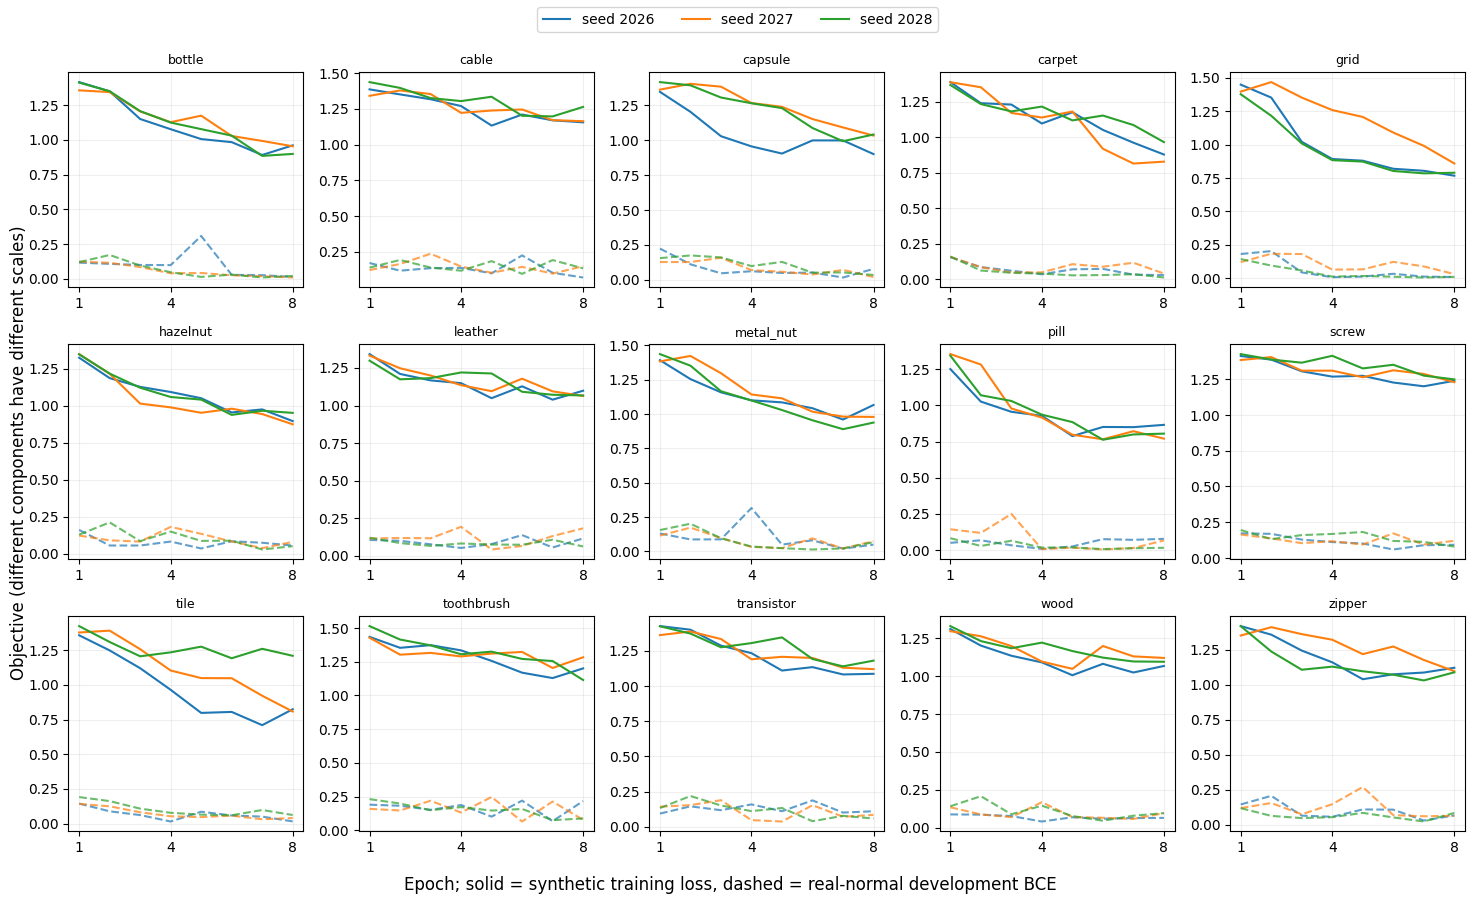

In [26]:
category_means=pd.read_csv(REPORT/"all_category_means.csv").set_index("category")
display(category_means.reindex(CATEGORIES))
display(pd.read_csv(REPORT/"macro_by_seed.csv"))
category_means[["image_auroc_mean","image_ap_mean","pixel_auroc_mean","pixel_ap_mean","au_pro_mean"]].plot.bar(figsize=(13,5),ylim=(0,1))
plt.ylabel("Metric");plt.title("Frozen Basic CNN: every category, mean over three seeds")
plt.legend(fontsize=8,loc="upper left",bbox_to_anchor=(1.01,1));plt.tight_layout();plt.savefig(OUT/"all_category_metrics.png",dpi=100);plt.show()
prevalence=[]
for category in CATEGORIES:
    r=evaluations[(category,2026)]
    prevalence.append({"category":category,"image_defect_prevalence":counts.loc[category,"test_defective"]/(counts.loc[category,"test_normal"]+counts.loc[category,"test_defective"]),
                       "pixel_foreground_prevalence":r["positive_pixels"]/(r["positive_pixels"]+r["negative_pixels"]),
                       "image_AP_mean":category_means.loc[category,"image_ap_mean"],"pixel_AP_mean":category_means.loc[category,"pixel_ap_mean"]})
display(pd.DataFrame(prevalence))

# All 45 frozen final learning histories; no new fitting occurs.
fig,axes=plt.subplots(3,5,figsize=(15,9))
colors=["tab:blue","tab:orange","tab:green"]
for ax,category in zip(axes.flat,CATEGORIES):
    for color,seed in zip(colors,frozen["seeds"]):
        identifier=f"01-final-{frozen['selected_variant']}-{category}-s{seed}-v1"
        run=json.loads((REPORT/f"runs/{identifier}-result.json").read_text())
        assert sha256(ROOT/run["history"])==run["history_sha256"]
        curve=pd.read_csv(ROOT/run["history"])
        ax.plot(curve.epoch,curve.train_loss,color=color,label=f"seed {seed}")
        ax.plot(curve.epoch,curve.normal_development_bce,color=color,linestyle="--",alpha=.7)
    ax.set_title(category,fontsize=9);ax.set_xticks([1,4,8]);ax.grid(alpha=.2)
fig.legend(*axes.flat[0].get_legend_handles_labels(),loc="upper center",ncol=3)
fig.supxlabel("Epoch; solid = synthetic training loss, dashed = real-normal development BCE")
fig.supylabel("Objective (different components have different scales)")
plt.tight_layout(rect=(0,0,1,.96));plt.savefig(OUT/"all_final_learning_curves.png",dpi=100);plt.show()


No success-only average, excluded category or favorable seed is substituted
for the full comparison. Three-seed spread describes model variation; the 2,000
image-bootstrap replicates describe sampling uncertainty conditional on these
models. Neither creates independent new inspection data. All raw operating-point
counts and per-defect outcomes remain available for independent review.

The final learning grid shows all three seeds for every category. Low normal-development BCE or improving synthetic loss does not imply successful real-defect transfer. All eight-epoch histories and the rejected development histories remain public CSV artifacts.

## 27. Conclusions, limits and next-model recommendations

Assess hypotheses against actual results rather than a favorable headline.
The complete machine-readable record covers configuration search, calibration,
frozen metrics, uncertainty, efficiency and every category/seed. This notebook
does not advertise a deployment-ready detector or silently begin another model.

In [27]:
display(metric_summary)
print("Completed development fits:",20,"fresh final models:",len(all_runs))
print("Configuration changed after test:",metric_summary["configuration_changed_after_test"])
print("Artifact manifest SHA256:",metric_summary["artifact_manifest_sha256"])
print("Local full notebook: outputs/basic_cnn/01_basic_cnn.executed.ipynb")
print("Notebook 02 and other architectures: not started.")

{'categories': 15,
 'seeds': [2026, 2027, 2028],
 'models': 45,
 'development_runs': 20,
 'frozen_configuration_sha256': '13b8d6a81a4e0f40af8732bd4ad58376554b6006ce0bb0126b13f9e105fb4404',
 'macro': {'image_auroc': {'mean': 0.7125886726666639,
   'seed_std': 0.021535018736352454,
   'image_bootstrap_95ci': [0.6950766876490477, 0.7303867835312444],
   'bootstrap_target': 'exact image metric',
   'valid_macro_replicates': 2000},
  'image_ap': {'mean': 0.858954308791314,
   'seed_std': 0.012582879520385733,
   'image_bootstrap_95ci': [0.8461642417521088, 0.8760253076423806],
   'bootstrap_target': 'exact image metric',
   'valid_macro_replicates': 2000},
  'pixel_auroc': {'mean': 0.7858321555450997,
   'seed_std': 0.024923187128343315,
   'image_bootstrap_95ci': [0.7779351759327134, 0.795878987262732],
   'bootstrap_target': '4096-bin pixel approximation',
   'valid_macro_replicates': 2000},
  'pixel_ap': {'mean': 0.23538242897890924,
   'seed_std': 0.010391394327386064,
   'image_bootstr

Completed development fits: 20 fresh final models: 45
Configuration changed after test: False
Artifact manifest SHA256: d6ad4007827f12603d3e9d4880eafa47effc1fbd3928b6a7acd7d29a6a548e38
Local full notebook: outputs/basic_cnn/01_basic_cnn.executed.ipynb
Notebook 02 and other architectures: not started.


**Observed frozen macro means over 15 categories and three seeds:** image
AUROC 0.7126, image AP 0.8590,
pixel AUROC 0.7858, pixel AP 0.2354,
AU-PRO 0.5498. Calibrated recall is
0.4018 and FPR 0.0983.
The lowest mean image-AUROC categories are screw (0.199), cable (0.506), capsule (0.527).
These outcomes are retained without changing the selected configuration.

The pilot establishes synthetic learning, not reliable real-defect detection.
The gap between proxy success and benchmark outcomes must be interpreted together
with category prevalence, false alarms, misses, weak small-defect localization and
the limited scratch representation. These are observational failure hypotheses,
not proven causal mechanisms. No pretrained backbone was used.

**Next recommendation:** a separately requested convolutional autoencoder study
can test a different normal-only learning objective; later pretrained-feature
methods test representation transfer. Neither is implemented here. Do not start
Notebook 02 automatically. Preserve the rejected CNN configurations and all final
results as the reference for later comparisons.